# Phase III — betweenness & ablation (unified)

Reads healed graphs from **Phase II unified** — folder picked via `MODEL_NAME`, same as Phase I/II — finds gatekeeper nodes, simulates knocking them out.

Outputs:
- `analysis_<MODEL_NAME>/{id}_criticality.json`
- `analysis_viz_<MODEL_NAME>/{id}_criticality.png`

Runs fine on CPU — set your Colab runtime type to CPU (Runtime → Change runtime type → None) to save your GPU quota for Phase I. Copy the JSON into `phase4/dashboard/public/data/` for the UI.


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
%matplotlib inline

import subprocess
subprocess.run(["pip", "install", "-q", "networkx", "numpy", "matplotlib"], check=True)
print("imports ok")


imports ok


In [3]:
import glob
import os

DRIVE_BASE = "/content/drive/MyDrive/RouteResilience"

MODEL_NAME = "deeplabv3"  # <-- change me: deeplabv3 | unetpp | unext | segformer | dinov2 | mfuser | denseddsspp | sam_repaired

# Matches Phase II unified's own tagging: GRAPH_DIR = f"{DRIVE_BASE}/outputs/graphs_{MODEL_NAME}"
GRAPH_DIR = os.path.join(DRIVE_BASE, f"outputs/graphs_{MODEL_NAME}")
ANALYSIS_DIR = os.path.join(DRIVE_BASE, f"outputs/analysis_{MODEL_NAME}")
VIS_DIR = os.path.join(DRIVE_BASE, f"outputs/analysis_viz_{MODEL_NAME}")

TOP_K = 5
WEIGHT_ATTR = "length"  # edge field in Phase II graph JSON

os.makedirs(ANALYSIS_DIR, exist_ok=True)
os.makedirs(VIS_DIR, exist_ok=True)

graph_files = sorted(glob.glob(os.path.join(GRAPH_DIR, "*_graph.json")))
if not graph_files:
    raise FileNotFoundError(
        f"No graph JSON files found in {GRAPH_DIR}.\n"
        f"Run MODEL_NAME='{MODEL_NAME}' in Phase II unified first (it writes graphs_{MODEL_NAME}/*.json)."
    )

print(f"MODEL_NAME:   {MODEL_NAME}")
print(f"GRAPH_DIR:    {GRAPH_DIR}")
print(f"ANALYSIS_DIR: {ANALYSIS_DIR}")
print(f"VIS_DIR:      {VIS_DIR}")
print(f"Found {len(graph_files)} graph file(s):")
for p in graph_files:
    print(f"  - {os.path.basename(p)}")


MODEL_NAME:   deeplabv3
GRAPH_DIR:    /content/drive/MyDrive/RouteResilience/outputs/graphs_deeplabv3
ANALYSIS_DIR: /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3
VIS_DIR:      /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3
Found 44 graph file(s):
  - 109889_graph.json
  - 127572_graph.json
  - 161528_graph.json
  - 188924_graph.json
  - 194764_graph.json
  - 288657_graph.json
  - 356917_graph.json
  - 375903_graph.json
  - 392410_graph.json
  - 393111_graph.json
  - 420624_graph.json
  - 422265_graph.json
  - 434989_graph.json
  - 435846_graph.json
  - 445532_graph.json
  - 44614_graph.json
  - 44984_graph.json
  - 452636_graph.json
  - 477671_graph.json
  - 493626_graph.json
  - 502218_graph.json
  - 511525_graph.json
  - 54635_graph.json
  - 55062_graph.json
  - 597644_graph.json
  - 616654_graph.json
  - 632438_graph.json
  - 642961_graph.json
  - 666341_graph.json
  - 684145_graph.json
  - 742461_graph.json
  - 77085_graph.json
  - 774511_

## Satellite image source (for plotting)

Same Kaggle-download pattern as Phase I/II unified — lets `plot_criticality` draw the criticality overlay on top of the actual tile instead of on a blank background. Skip re-downloading if you're in the same runtime session right after Phase I/II (files still on disk).


In [4]:
import subprocess
import zipfile

LOCAL_DATA_ROOT = "/content/data"
LOCAL_TRAIN_DIR = f"{LOCAL_DATA_ROOT}/train"
DATA_DIR = LOCAL_TRAIN_DIR

if not os.path.isdir(LOCAL_TRAIN_DIR) or not os.listdir(LOCAL_TRAIN_DIR):
    subprocess.run(["pip", "install", "-q", "kaggle"], check=True)

    os.makedirs("/root/.kaggle", exist_ok=True)
    if not os.path.exists("/root/.kaggle/kaggle.json"):
        from google.colab import files
        print("Upload your kaggle.json API token:")
        uploaded = files.upload()
        for fname in uploaded:
            os.rename(fname, "/root/.kaggle/kaggle.json")
    os.chmod("/root/.kaggle/kaggle.json", 0o600)

    KAGGLE_DATASET = "balraj98/deepglobe-road-extraction-dataset"  # match Phase I/II unified
    os.makedirs(LOCAL_DATA_ROOT, exist_ok=True)
    subprocess.run(
        ["kaggle", "datasets", "download", "-d", KAGGLE_DATASET, "-p", LOCAL_DATA_ROOT],
        check=True,
    )
    zips = [f for f in os.listdir(LOCAL_DATA_ROOT) if f.endswith(".zip")]
    with zipfile.ZipFile(f"{LOCAL_DATA_ROOT}/{zips[0]}") as zf:
        zf.extractall(LOCAL_DATA_ROOT)
    print("Extracted to", LOCAL_DATA_ROOT)
else:
    print("Local data already present at", LOCAL_TRAIN_DIR)

print("Data dir:", DATA_DIR)


Upload your kaggle.json API token:


Saving kaggle.json to kaggle.json
Extracted to /content/data
Data dir: /content/data/train


In [5]:
import json
import cv2
import networkx as nx


def image_id_from_path(path):
    return os.path.basename(path).replace("_graph.json", "")


def load_graph_from_json(path, weight_attr=WEIGHT_ATTR):
    """Load Phase II graph JSON; map edge length -> NetworkX weight."""
    with open(path, "r") as f:
        data = json.load(f)

    G = nx.Graph()
    for n in data.get("nodes", []):
        G.add_node(
            n["id"],
            x=n["x"],
            y=n["y"],
            degree=n.get("degree"),
        )

    for e in data.get("edges", []):
        w = float(e.get(weight_attr, e.get("weight", 1.0)))
        G.add_edge(
            e["source"],
            e["target"],
            weight=w,
            length=w,
            coords=e.get("coords", []),
            healed=bool(e.get("healed", False)),
            edge_id=e.get("id", f"e{e['source']}_{e['target']}"),
        )

    image_id = data.get("image_id") or image_id_from_path(path)
    return G, image_id


def largest_component(G):
    """Return the largest connected subgraph (analysis target)."""
    if G.number_of_nodes() == 0:
        return G.copy()
    nodes = max(nx.connected_components(G), key=len)
    return G.subgraph(nodes).copy()





In [6]:
def compute_betweenness(G):
    """Betweenness with edge length as weight."""
    if G.number_of_nodes() < 2:
        return {}
    return nx.betweenness_centrality(G, weight="weight", normalized=True)


def rank_gatekeepers(G, bc, top_k=TOP_K):
    """Rank nodes by betweenness; return top-k gatekeeper records for the dashboard."""
    ranked = sorted(bc.items(), key=lambda item: item[1], reverse=True)
    gatekeepers = []
    for rank, (node_id, score) in enumerate(ranked[:top_k], start=1):
        attrs = G.nodes[node_id]
        gatekeepers.append({
            "id": node_id,
            "betweenness": round(float(score), 4),
            "rank": rank,
            "x": int(attrs.get("x", 0)),
            "y": int(attrs.get("y", 0)),
        })
    return gatekeepers, ranked


In [7]:
def avg_path_length(G):
    """Average shortest path over reachable pairs."""
    nodes = list(G.nodes())
    n = len(nodes)
    if n < 2:
        return 0.0

    total = 0.0
    count = 0
    for i, u in enumerate(nodes):
        for v in nodes[i + 1 :]:
            if nx.has_path(G, u, v):
                total += nx.shortest_path_length(G, u, v, weight="weight")
                count += 1
    if count == 0:
        return float("inf")
    return total / count


def resilience_index(baseline_len, perturbed_len):
    """R = L_baseline / L_perturbed (values > 1 mean network degraded)."""
    if perturbed_len is None or perturbed_len <= 0 or perturbed_len == float("inf"):
        return 0.0
    return round(baseline_len / perturbed_len, 4)


def simulate_node_removal(G, node_id):
    """Remove one node and return perturbed graph + summary metrics."""
    G2 = G.copy()
    if node_id in G2:
        G2.remove_node(node_id)
    return {
        "graph": G2,
        "avg_path_length": avg_path_length(G2),
        "connected_components": nx.number_connected_components(G2),
    }


def run_ablation_study(G, ranked_nodes, baseline_len, top_k=TOP_K):
    """Ablate top-k gatekeepers one at a time."""
    results = []
    for rank, (node_id, bc_score) in enumerate(ranked_nodes[:top_k], start=1):
        sim = simulate_node_removal(G, node_id)
        perturbed_len = sim["avg_path_length"]
        results.append({
            "removed_node": node_id,
            "avg_path_length": perturbed_len,
            "connected_components": sim["connected_components"],
            "resilience_index": resilience_index(baseline_len, perturbed_len),
            "rank": rank,
            "betweenness": round(float(bc_score), 4),
        })
    return results





In [8]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np


def edge_criticality(u, v, bc):
    return (bc.get(u, 0.0) + bc.get(v, 0.0)) / 2.0


def build_dashboard_json(image_id, G, gatekeepers, bc, baseline_len, ablation_results):
    """Assemble Phase IV-compatible criticality.json payload."""
    edges_out = []
    for u, v, data in G.edges(data=True):
        crit = edge_criticality(u, v, bc)
        edges_out.append({
            "id": data.get("edge_id", f"e{u}_{v}"),
            "source": u,
            "target": v,
            "criticality": round(float(crit), 4),
            "healed": bool(data.get("healed", False)),
            "coords": data.get("coords", []),
        })

    top = ablation_results[0] if ablation_results else {}
    baseline_cc = nx.number_connected_components(G)

    return {
        "image_id": image_id,
        "gatekeepers": gatekeepers,
        "edges": edges_out,
        "metrics": {
            "baseline_avg_path_length": round(float(baseline_len), 4),
            "perturbed_avg_path_length": round(float(top.get("avg_path_length", baseline_len)), 4),
            "resilience_index": top.get("resilience_index", 1.0),
            "baseline_connected_components": baseline_cc,
            "connected_components": top.get("connected_components", baseline_cc),
        },
        "ablation_study": ablation_results,
    }


def save_analysis(payload, analysis_dir=ANALYSIS_DIR):
    out_path = os.path.join(analysis_dir, f"{payload['image_id']}_criticality.json")
    with open(out_path, "w") as f:
        json.dump(payload, f, indent=2)
    print(f"Saved analysis -> {out_path}")
    return out_path


def plot_criticality(G, bc, image_id, sat_img=None, vis_dir=VIS_DIR):
    """Draw edge criticality heatmap + node betweenness sizing, on top of the satellite tile if given."""
    fig, ax = plt.subplots(figsize=(10, 10))
    if sat_img is not None:
        ax.imshow(sat_img)
    else:
        ax.set_facecolor("#1a1a2e")
        fig.patch.set_facecolor("#1a1a2e")

    crit_values = []
    edge_segments = []
    for u, v, data in G.edges(data=True):
        coords = data.get("coords", [])
        if len(coords) < 2:
            x0, y0 = G.nodes[u].get("x", 0), G.nodes[u].get("y", 0)
            x1, y1 = G.nodes[v].get("x", 0), G.nodes[v].get("y", 0)
            xs, ys = [x0, x1], [y0, y1]
        else:
            ys = [pt[0] for pt in coords]
            xs = [pt[1] for pt in coords]
        crit = edge_criticality(u, v, bc)
        crit_values.append(crit)
        edge_segments.append((xs, ys, crit, bool(data.get("healed", False))))

    vmax = max(crit_values) if crit_values else 1.0
    norm = mcolors.Normalize(vmin=0.0, vmax=max(vmax, 1e-6))
    cmap = matplotlib.colormaps["RdYlGn_r"]

    for xs, ys, crit, healed in edge_segments:
        color = cmap(norm(crit))
        ls = "--" if healed else "-"
        ax.plot(xs, ys, color=color, linewidth=1.5 if not healed else 1.0, alpha=0.85, linestyle=ls)

    node_x, node_y, sizes, colors = [], [], [], []
    for node_id, attrs in G.nodes(data=True):
        node_x.append(attrs.get("x", 0))
        node_y.append(attrs.get("y", 0))
        bc_val = bc.get(node_id, 0.0)
        sizes.append(20 + 300 * bc_val)
        colors.append(bc_val)

    sc = ax.scatter(node_x, node_y, s=sizes, c=colors, cmap="plasma", edgecolors="white", linewidths=0.3, zorder=5)
    cbar = plt.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=0.03, pad=0.02)
    cbar.set_label("Edge criticality", color="white")
    cbar.ax.yaxis.set_tick_params(color="white")
    plt.setp(plt.getp(cbar.ax.axes, "yticklabels"), color="white")

    ax.set_title(f"Criticality heatmap — {image_id}", color="white", fontsize=14)
    ax.set_aspect("equal")
    if sat_img is None:
        ax.invert_yaxis()  # imshow already sets top-down orientation when sat_img is given
    ax.axis("off")

    out_path = os.path.join(vis_dir, f"{image_id}_criticality.png")
    plt.tight_layout()
    plt.savefig(out_path, dpi=150, facecolor=fig.get_facecolor())
    plt.show()
    plt.close(fig)
    print(f"Saved heatmap -> {out_path}")
    return out_path






Analyzing 109889_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/109889_criticality.json


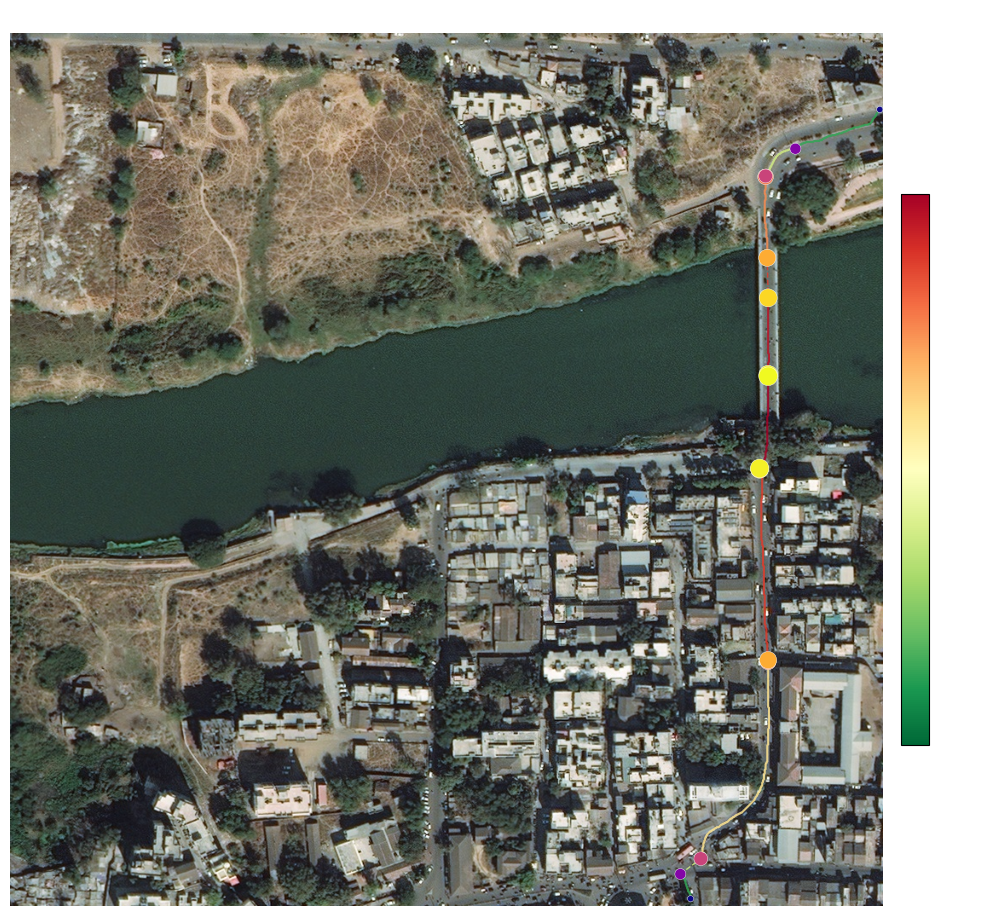

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/109889_criticality.png

Analyzing 127572_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/127572_criticality.json


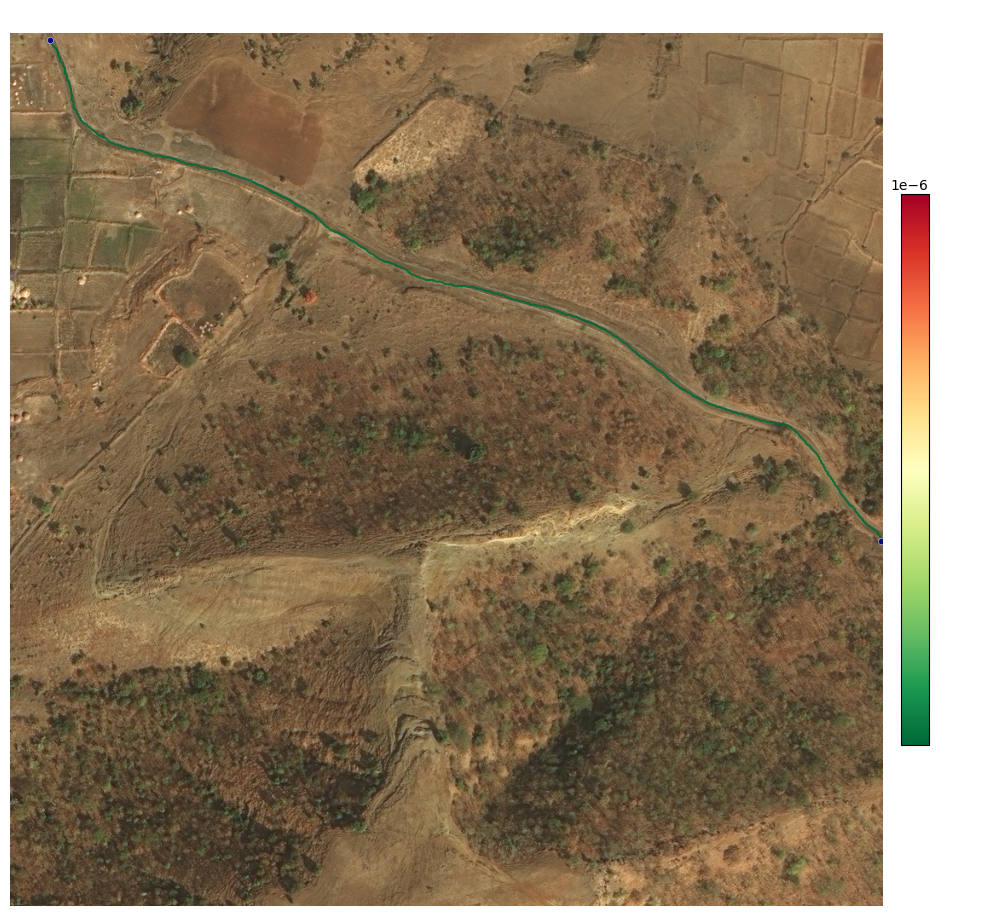

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/127572_criticality.png

Analyzing 161528_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/161528_criticality.json


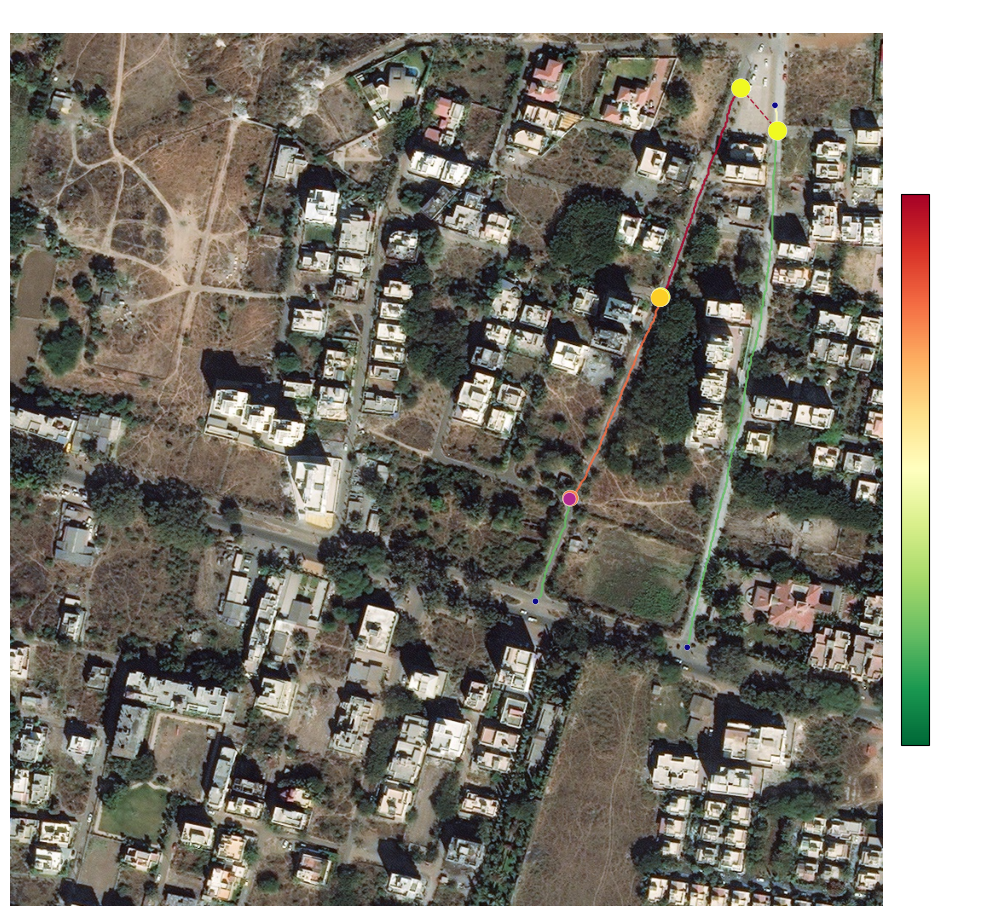

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/161528_criticality.png

Analyzing 188924_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/188924_criticality.json


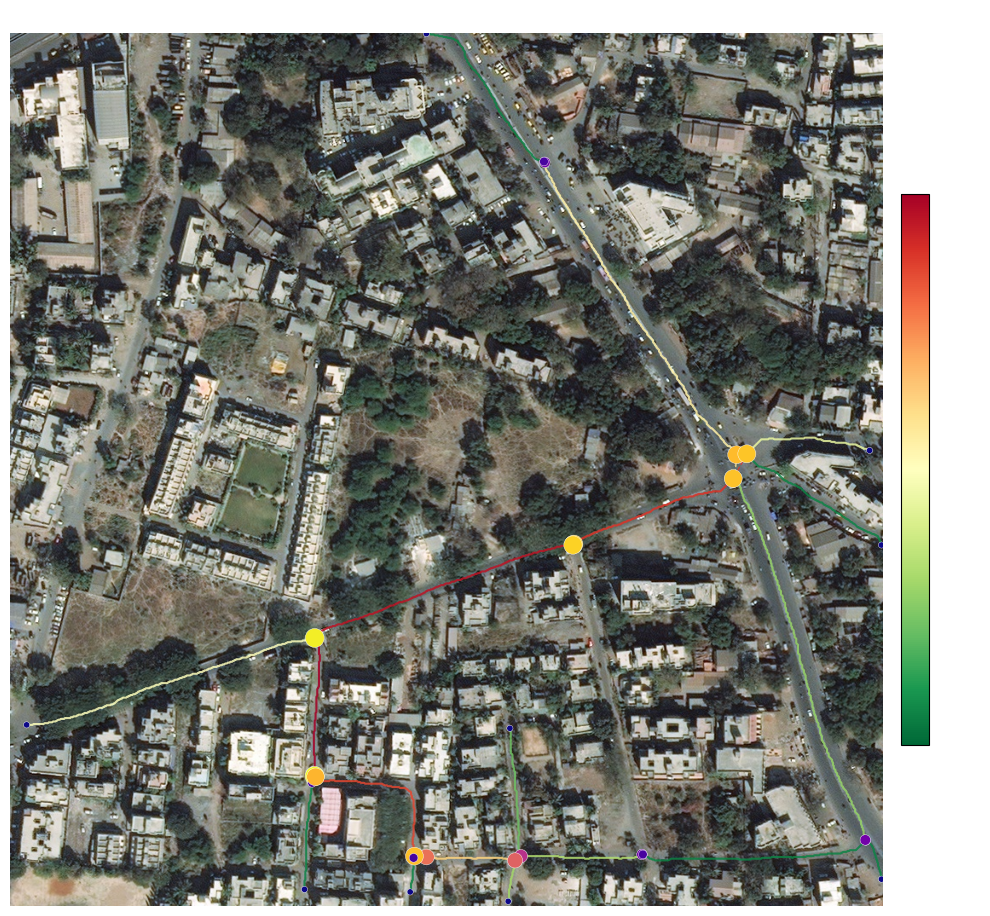

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/188924_criticality.png

Analyzing 194764_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/194764_criticality.json


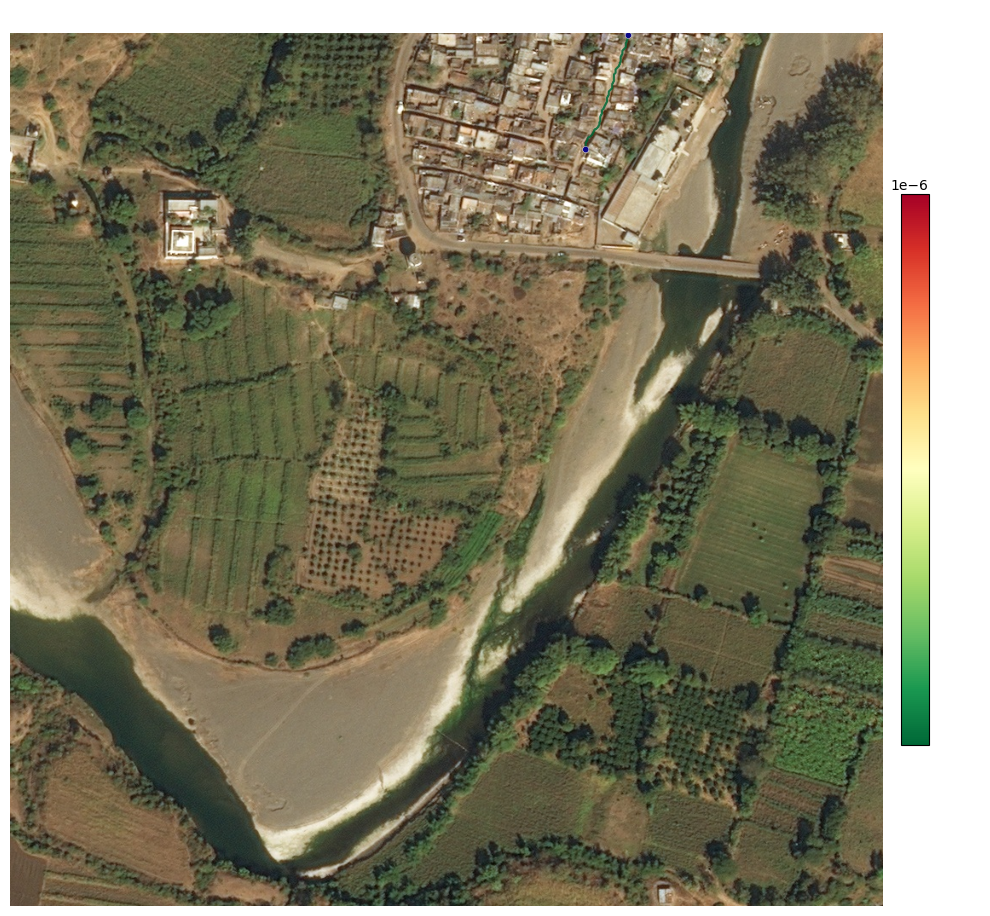

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/194764_criticality.png

Analyzing 288657_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/288657_criticality.json


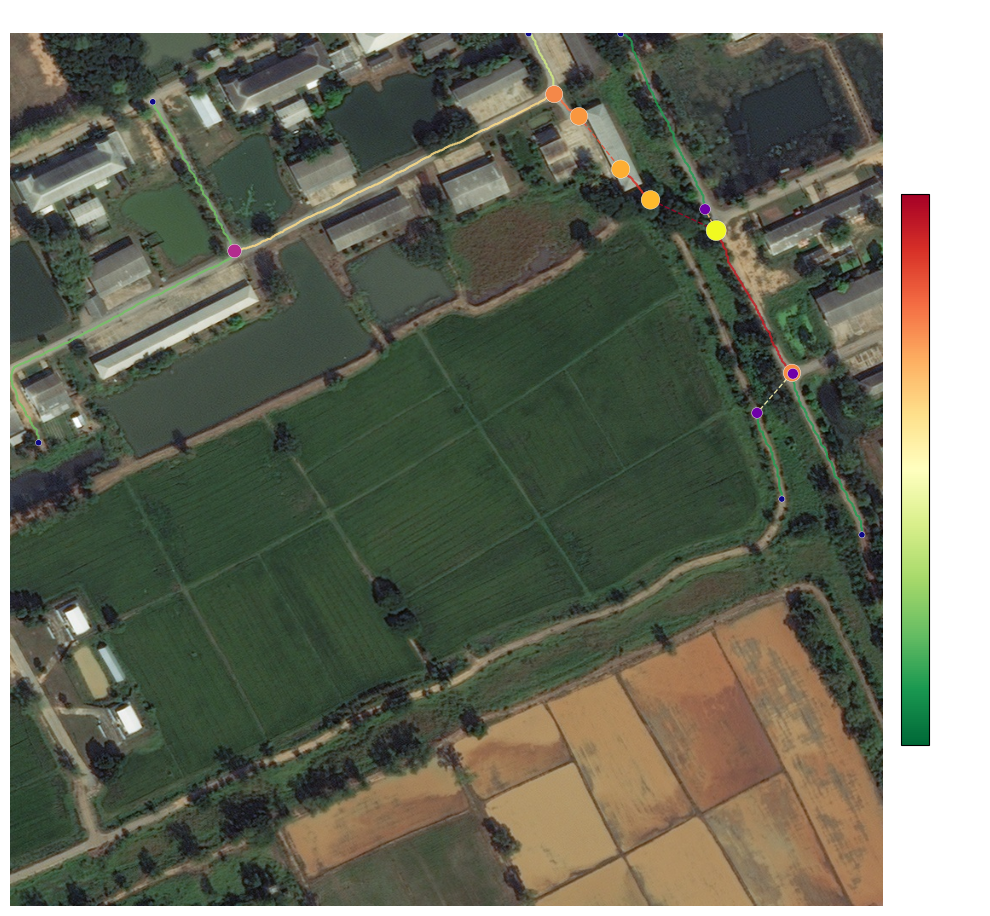

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/288657_criticality.png

Analyzing 356917_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/356917_criticality.json


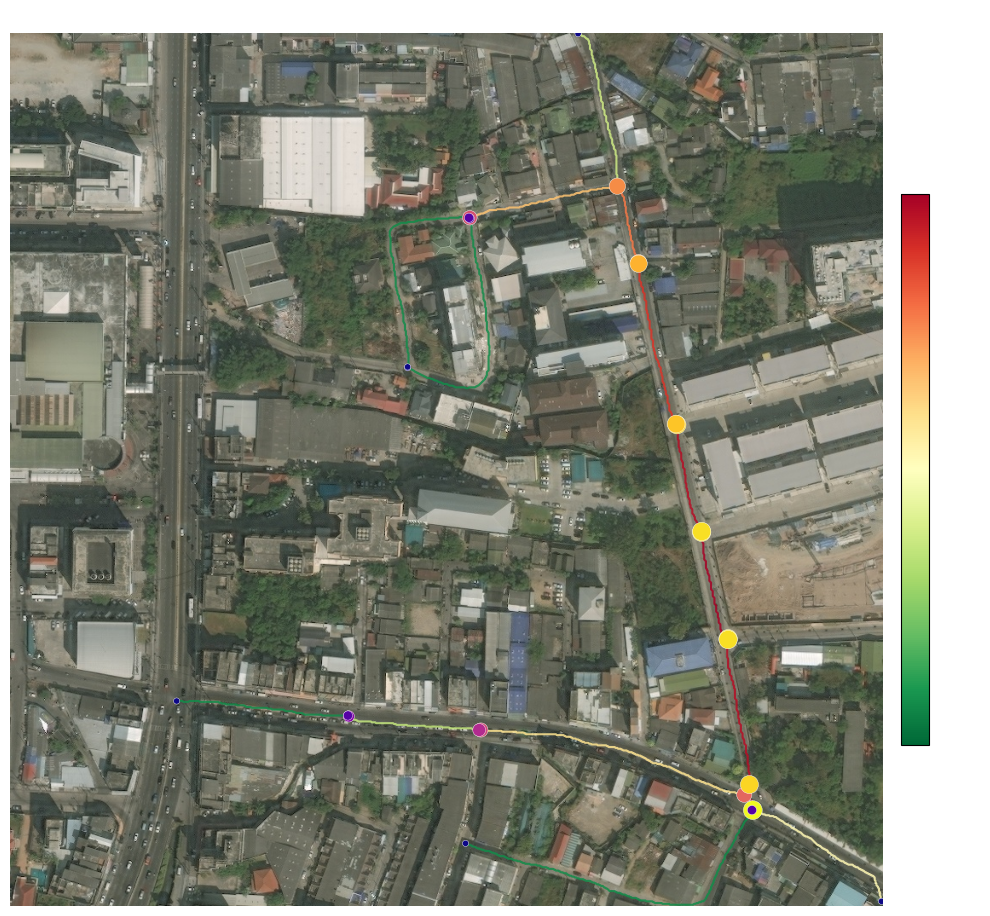

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/356917_criticality.png

Analyzing 375903_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/375903_criticality.json


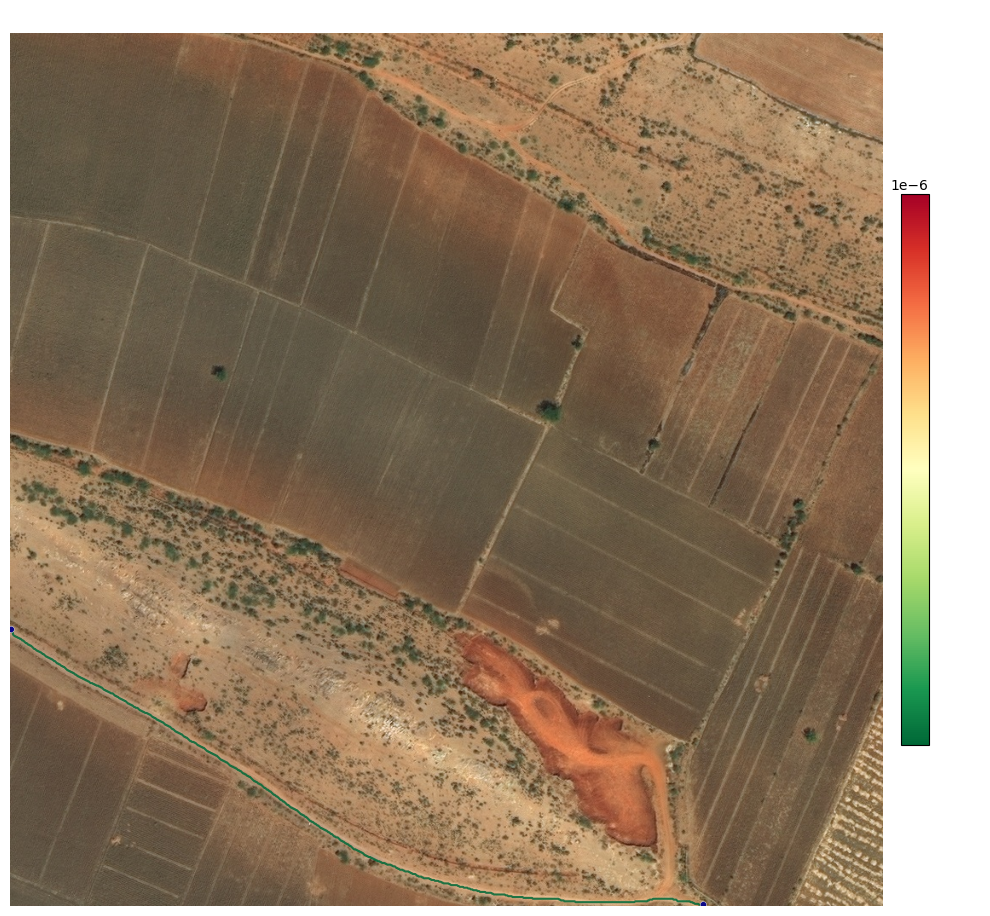

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/375903_criticality.png

Analyzing 392410_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/392410_criticality.json


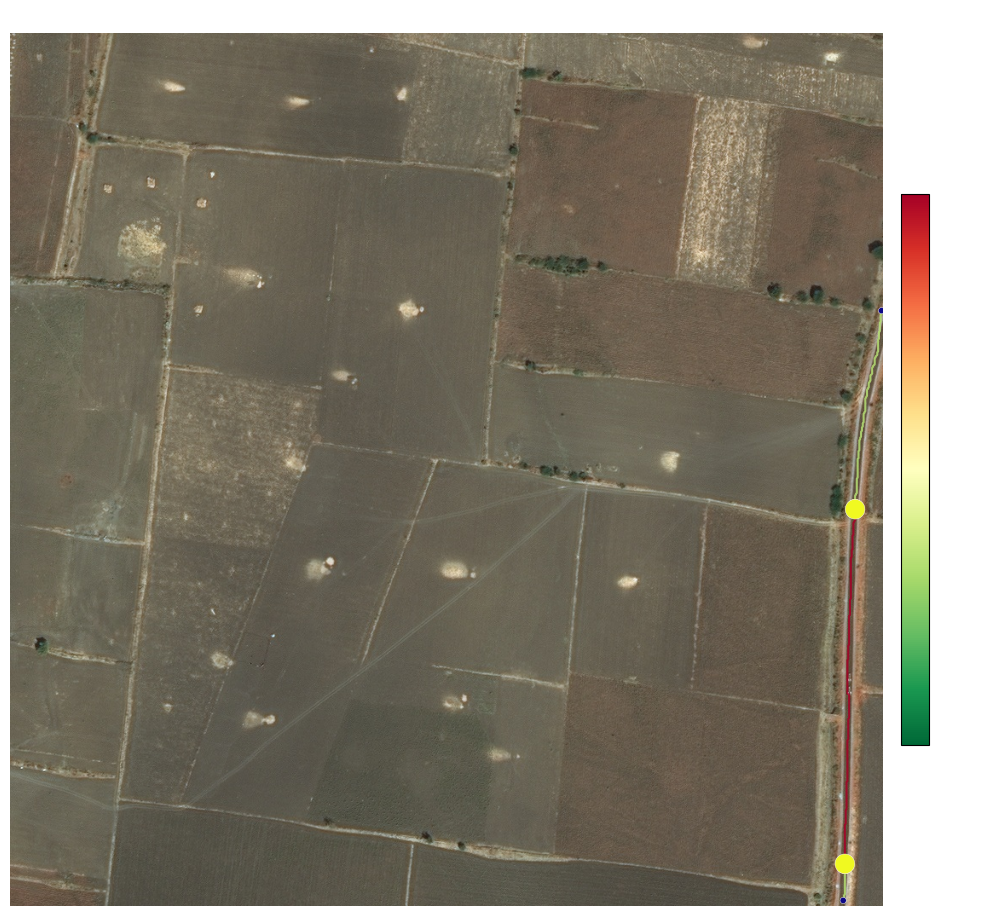

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/392410_criticality.png

Analyzing 393111_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/393111_criticality.json


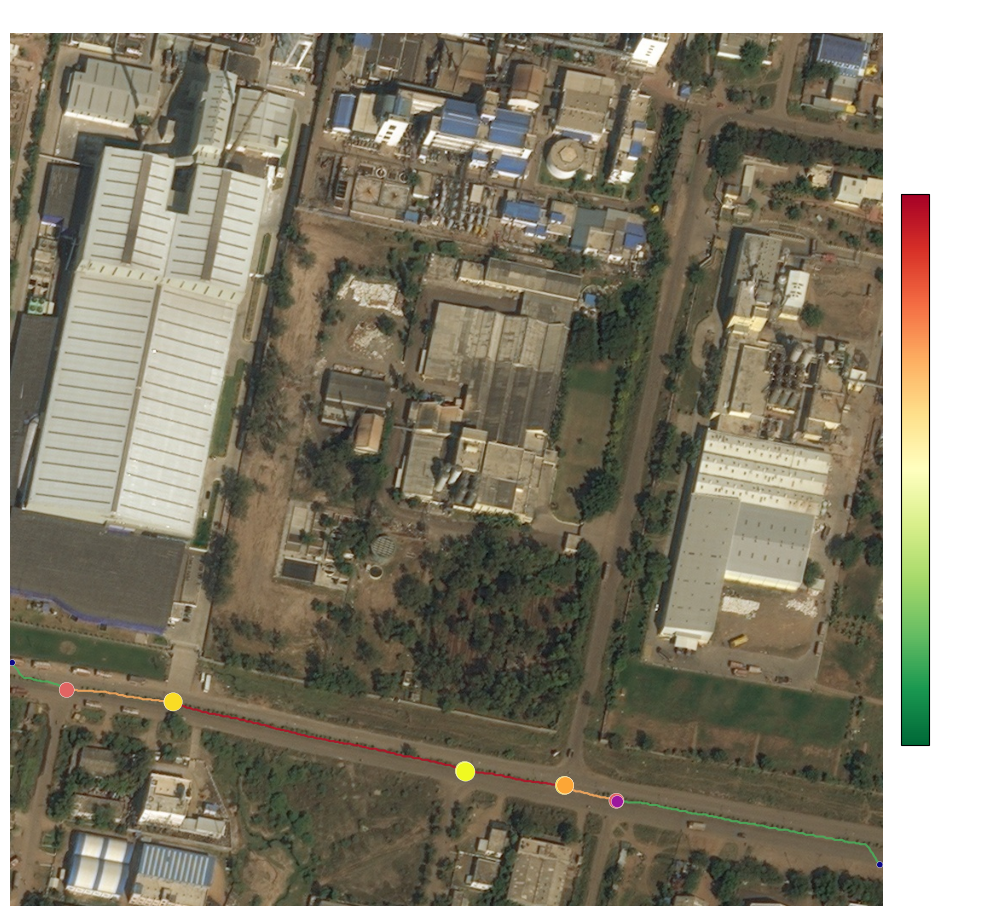

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/393111_criticality.png

Analyzing 420624_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/420624_criticality.json


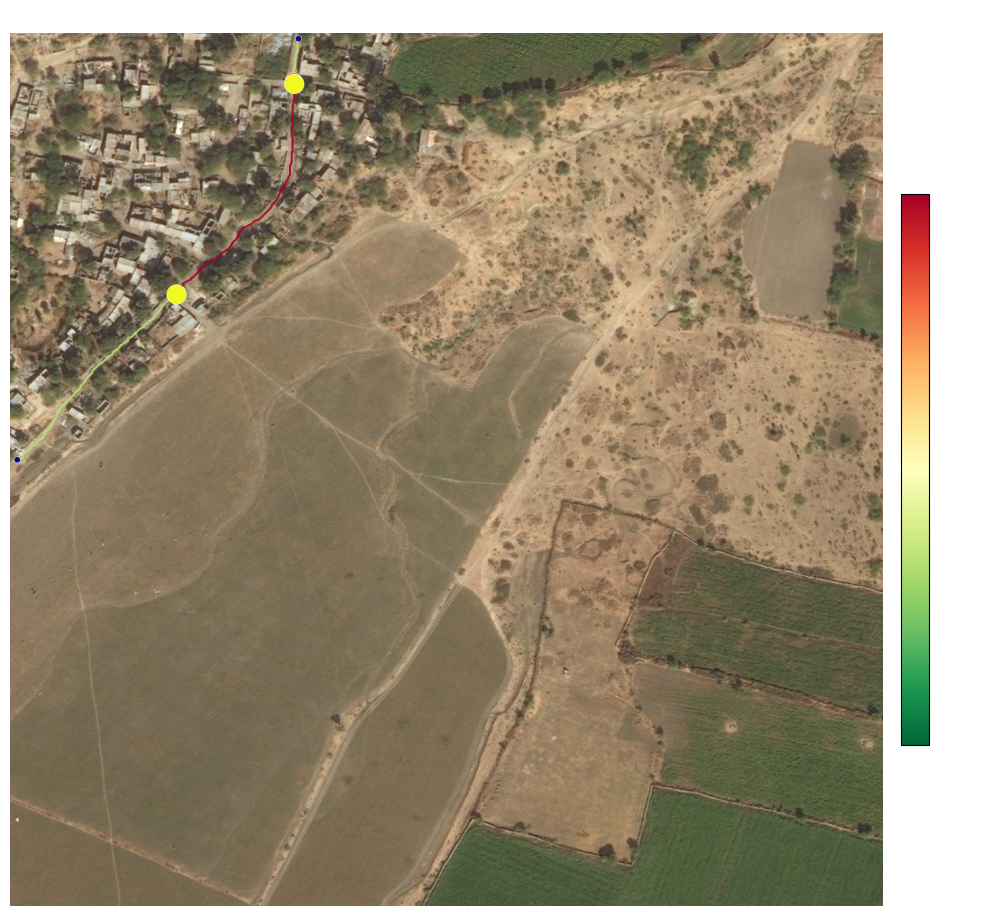

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/420624_criticality.png

Analyzing 422265_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/422265_criticality.json


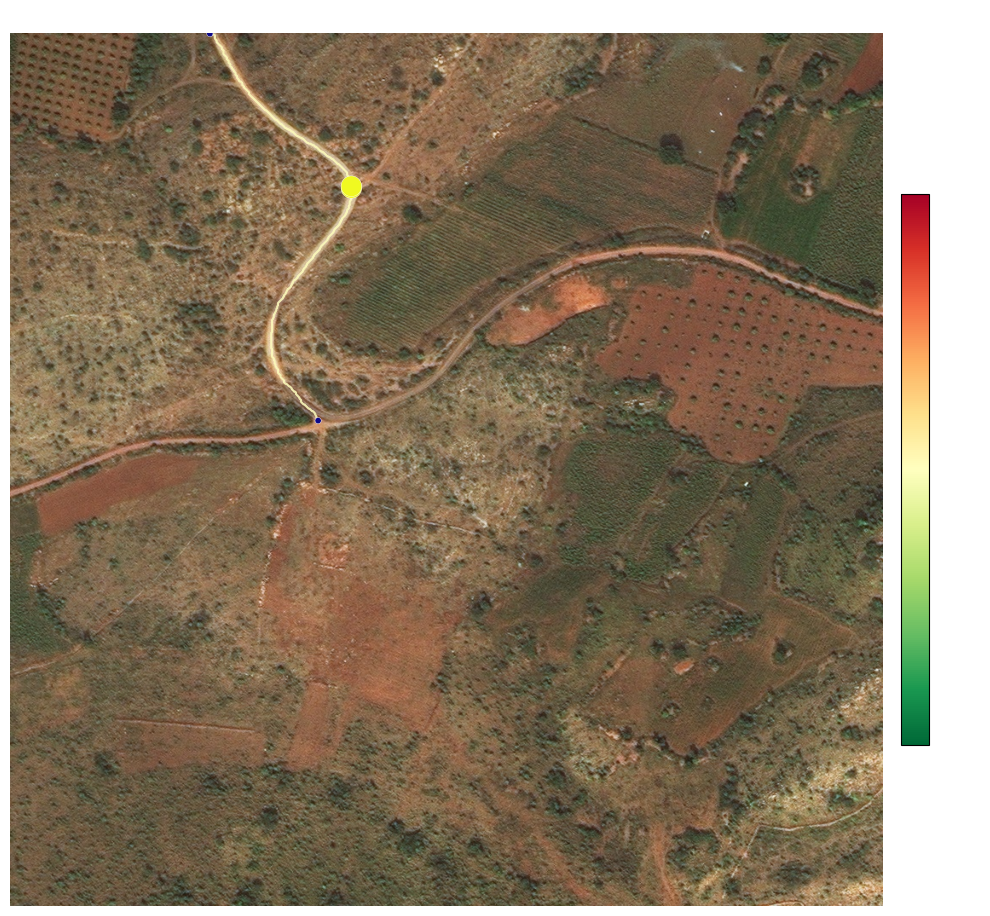

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/422265_criticality.png

Analyzing 434989_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/434989_criticality.json


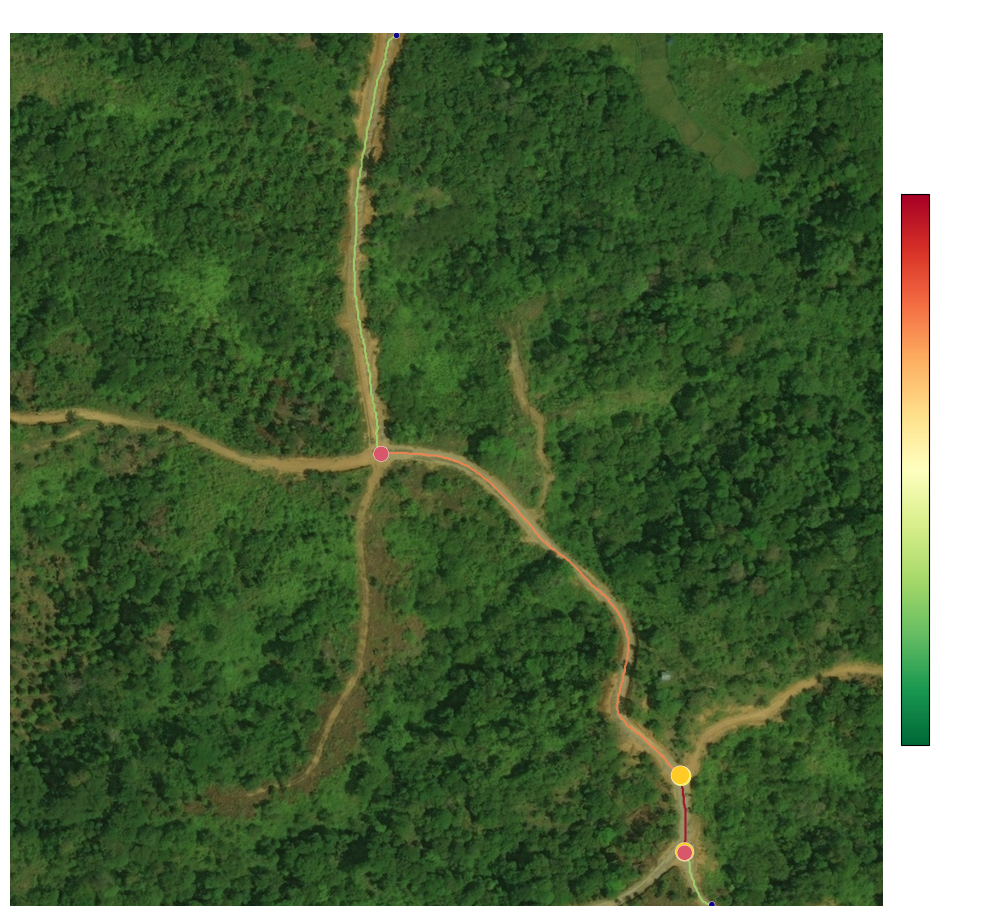

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/434989_criticality.png

Analyzing 435846_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/435846_criticality.json


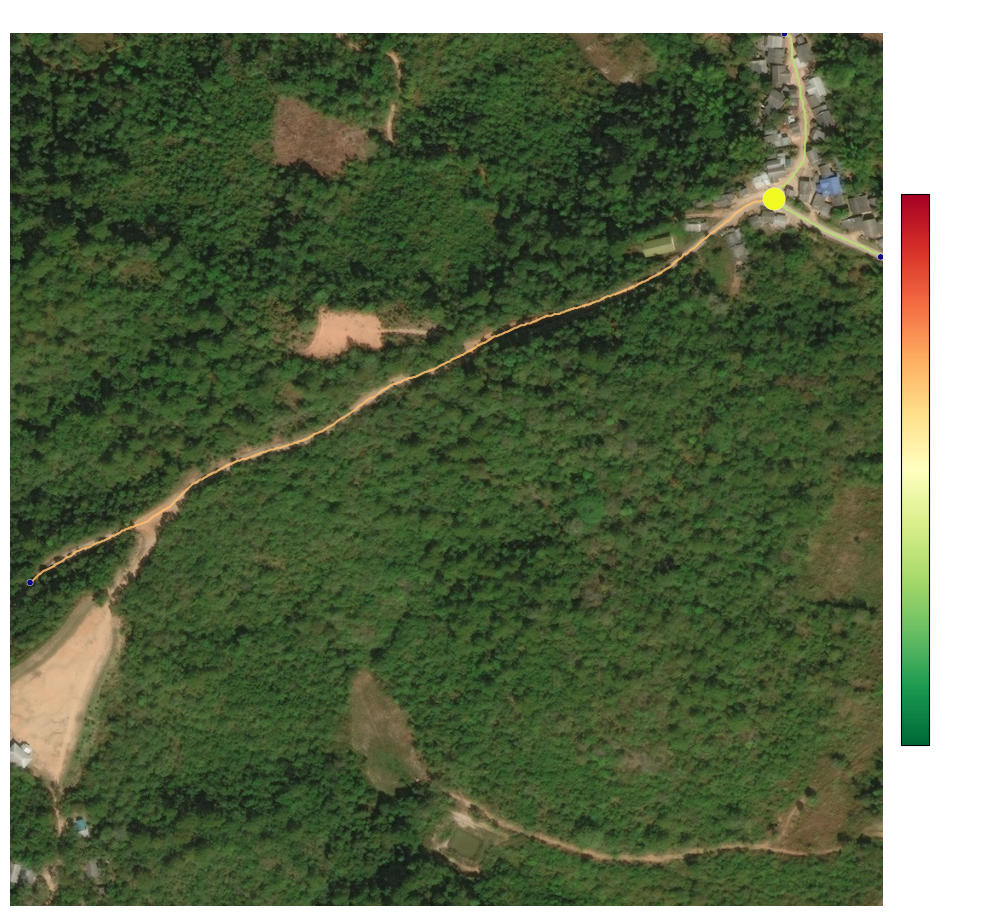

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/435846_criticality.png

Analyzing 445532_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/445532_criticality.json


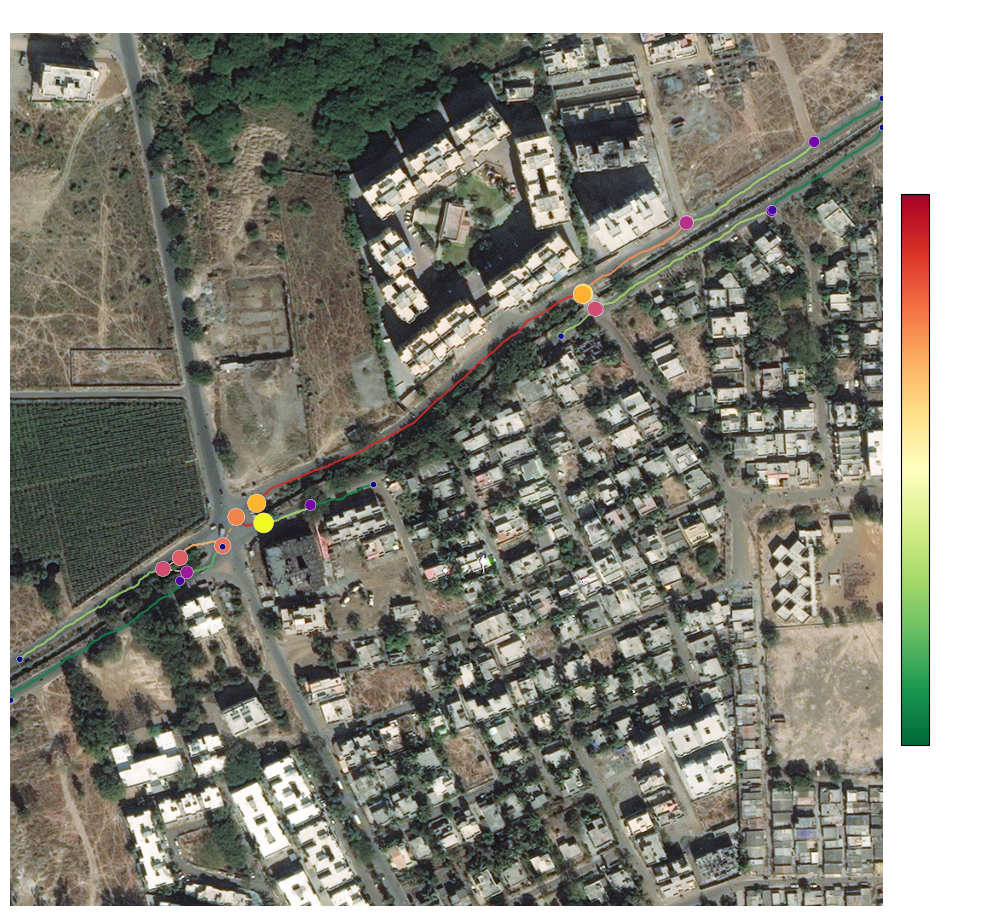

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/445532_criticality.png

Analyzing 44614_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/44614_criticality.json


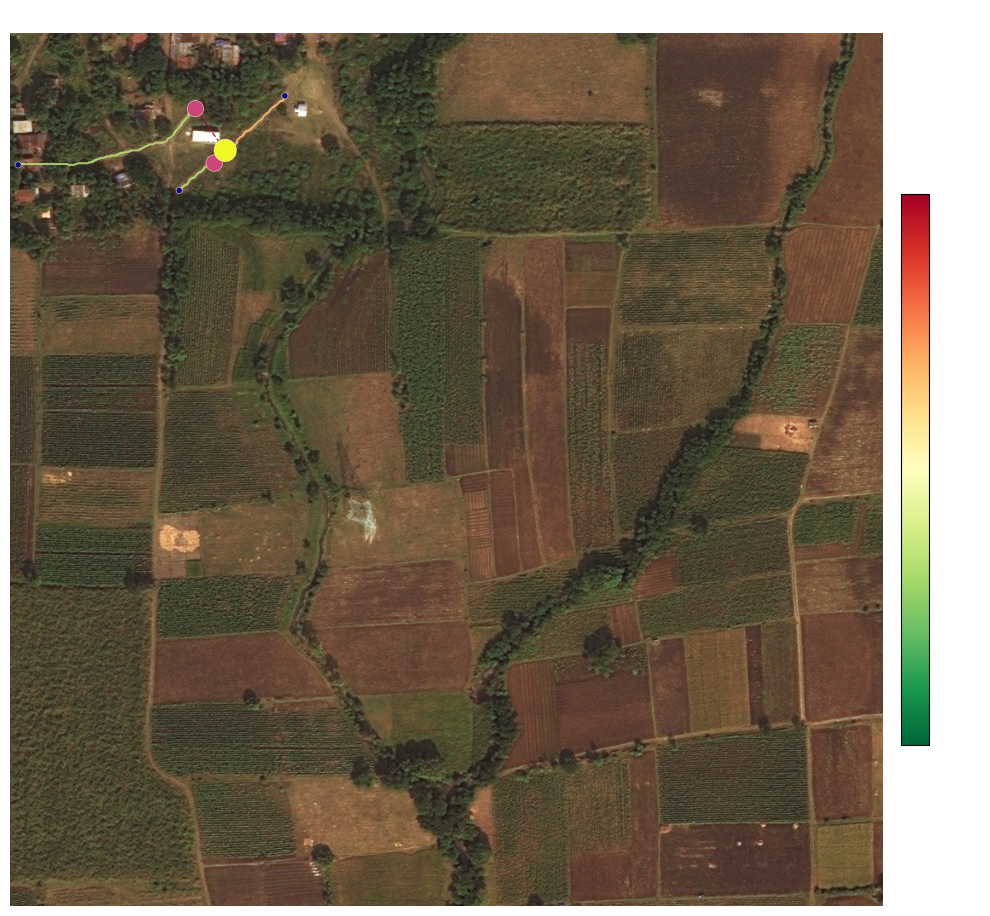

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/44614_criticality.png

Analyzing 44984_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/44984_criticality.json


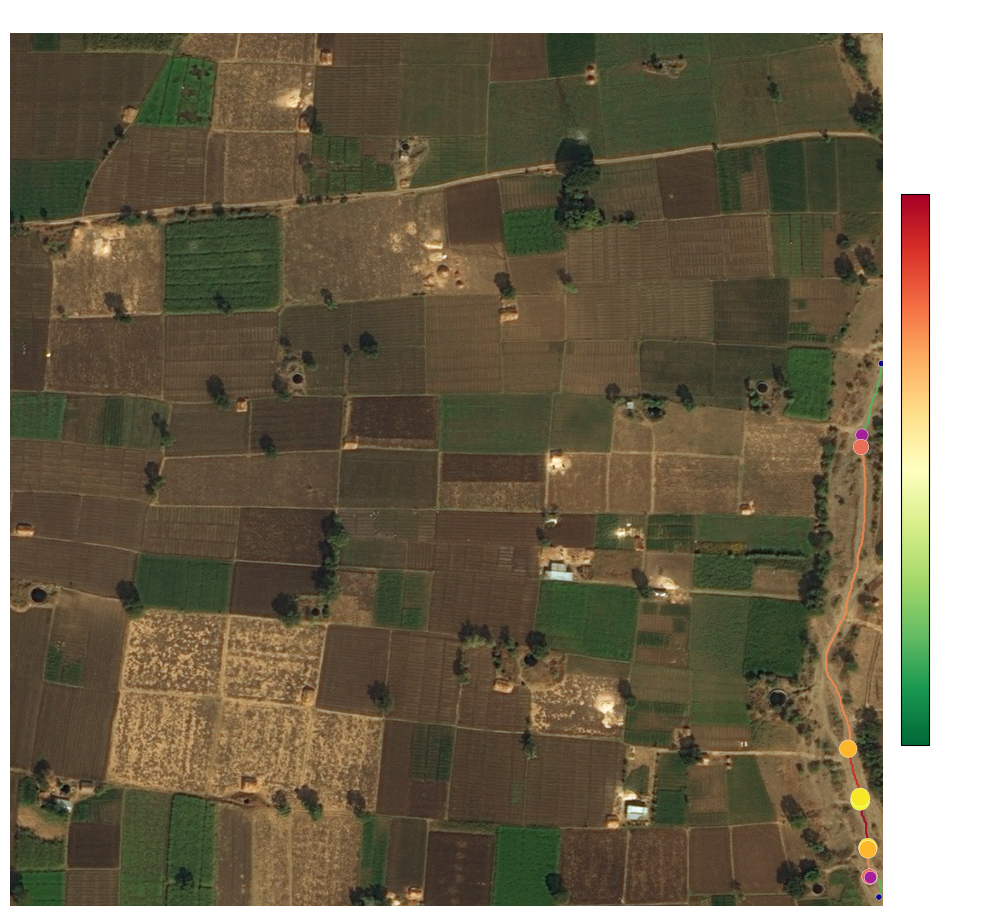

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/44984_criticality.png

Analyzing 452636_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/452636_criticality.json


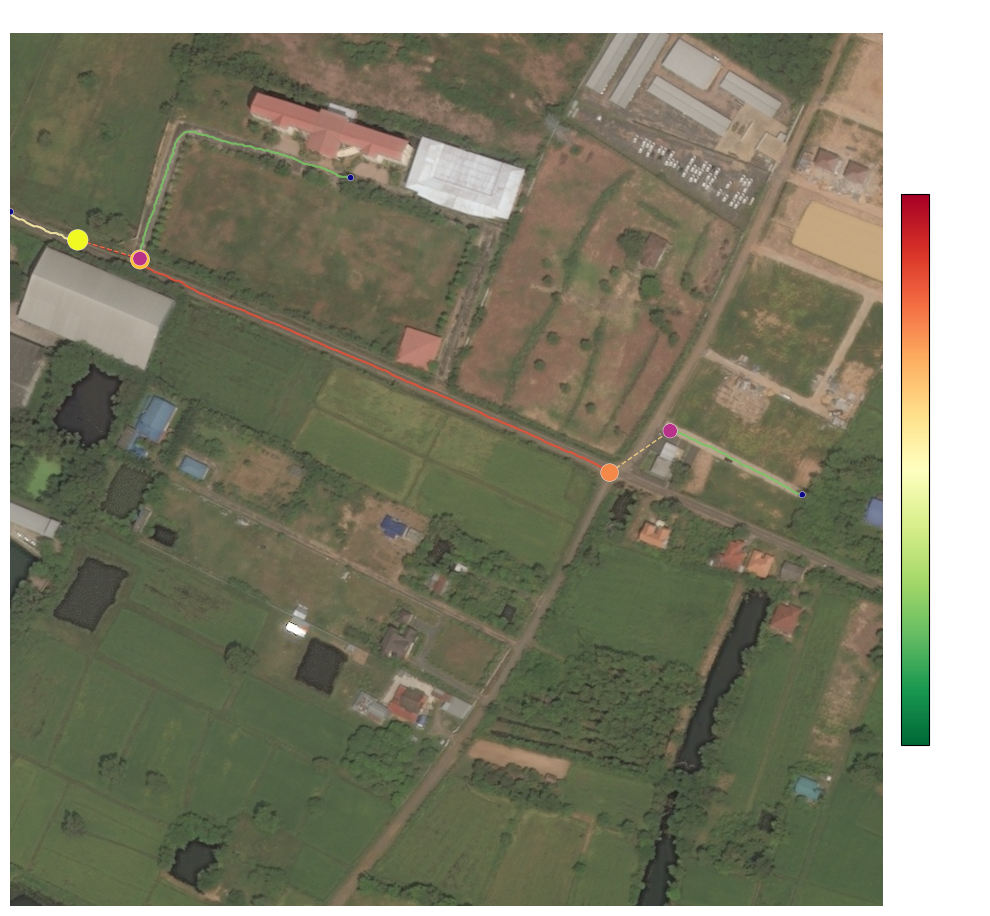

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/452636_criticality.png

Analyzing 477671_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/477671_criticality.json


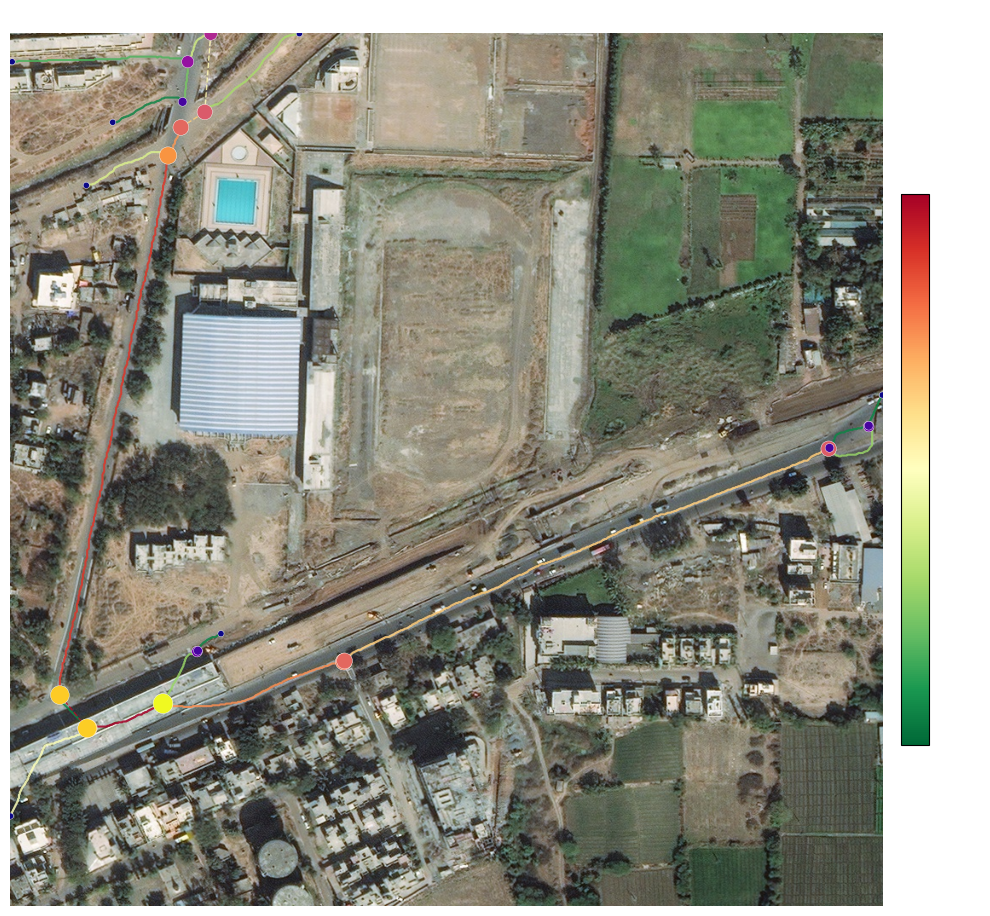

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/477671_criticality.png

Analyzing 493626_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/493626_criticality.json


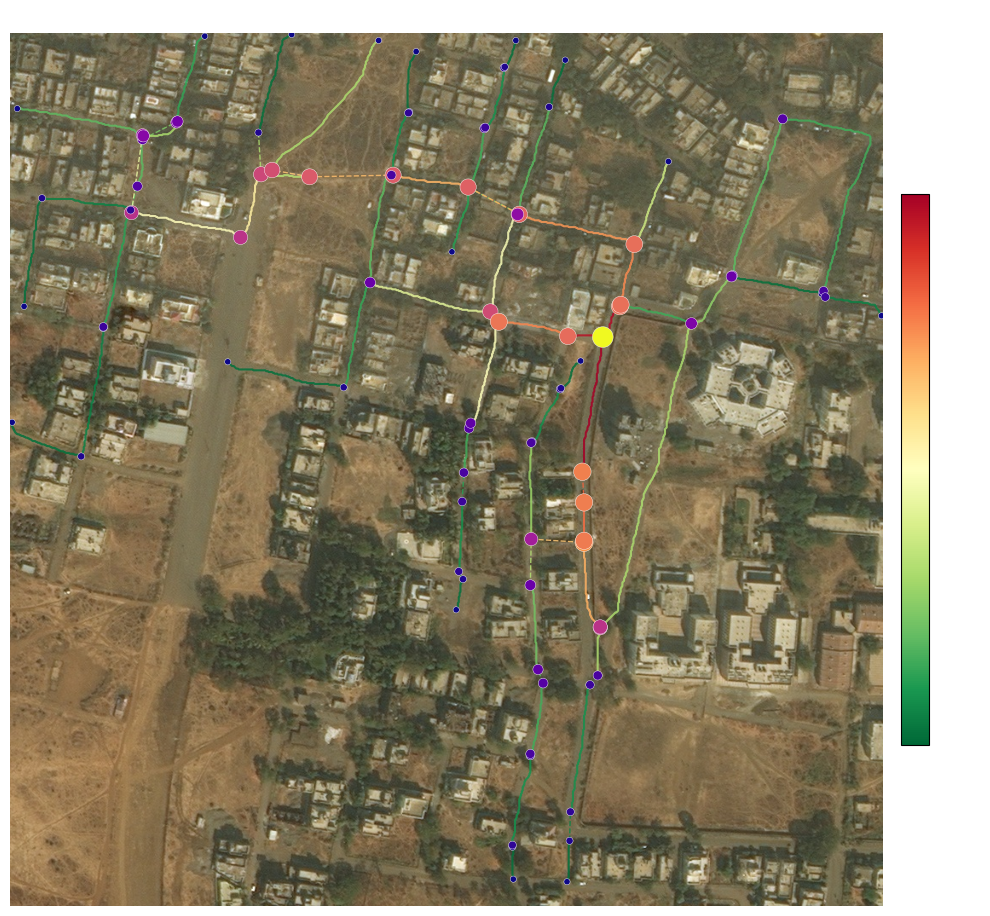

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/493626_criticality.png

Analyzing 502218_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/502218_criticality.json


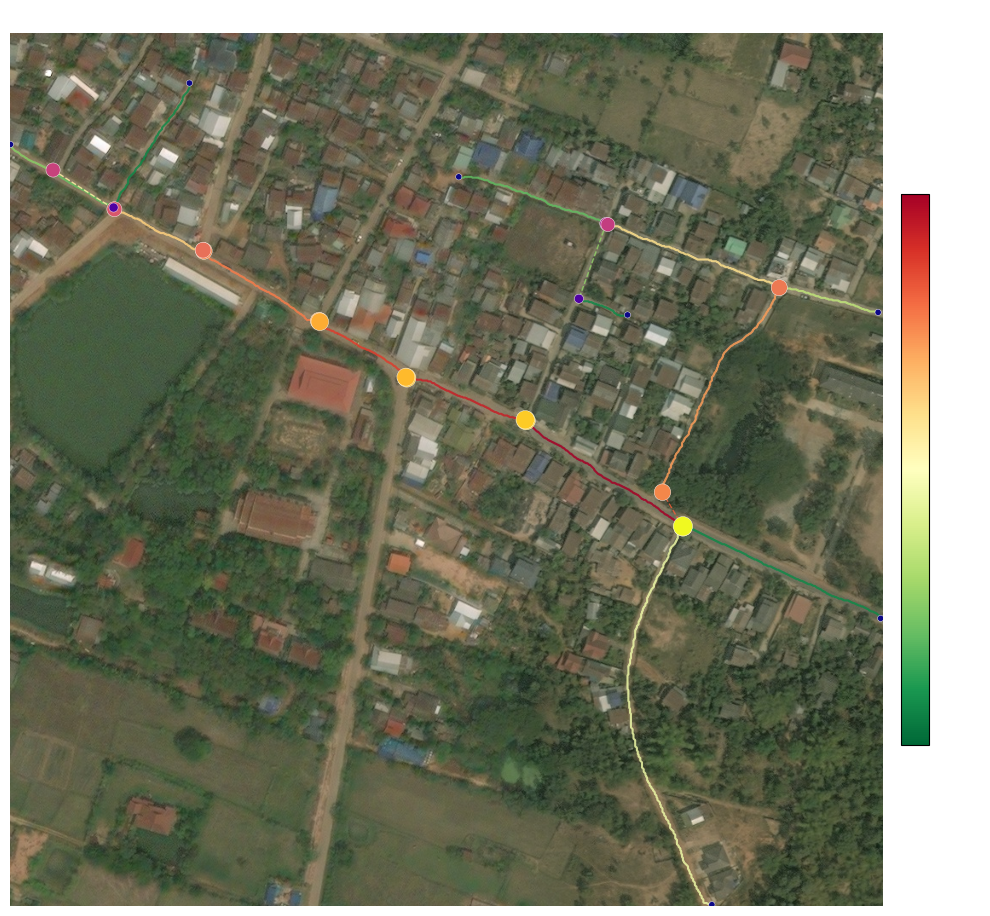

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/502218_criticality.png

Analyzing 511525_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/511525_criticality.json


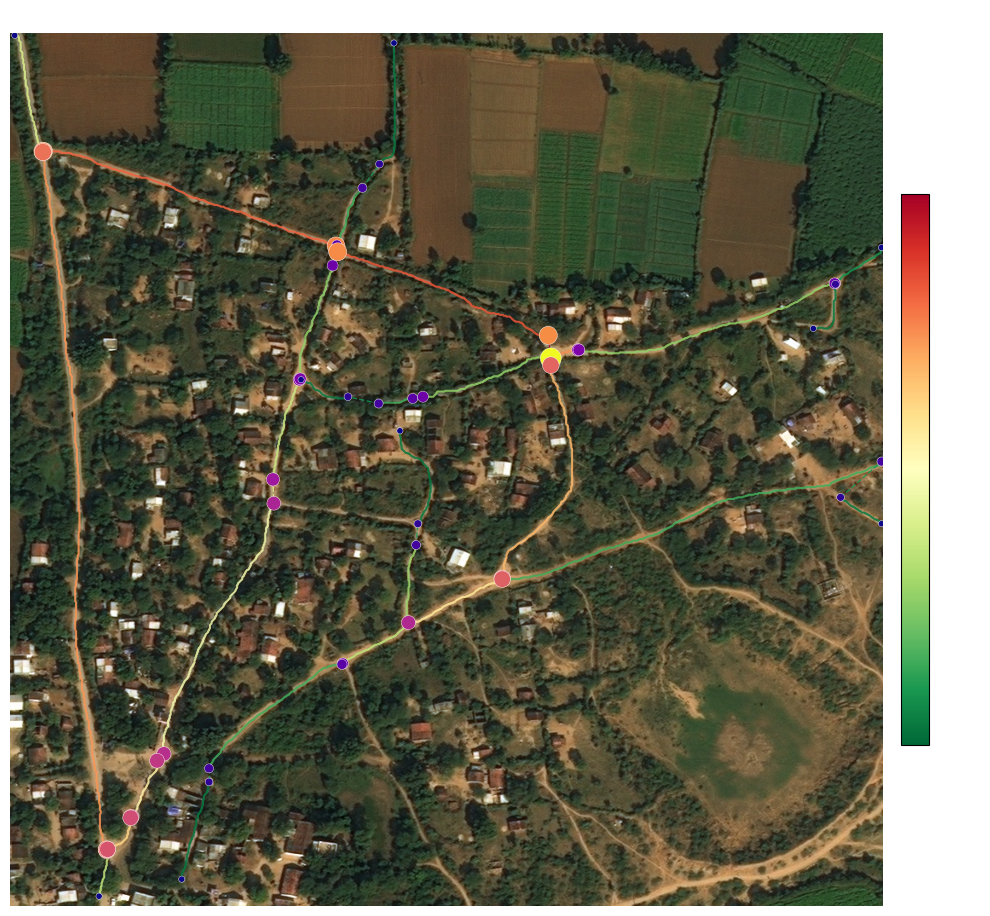

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/511525_criticality.png

Analyzing 54635_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/54635_criticality.json


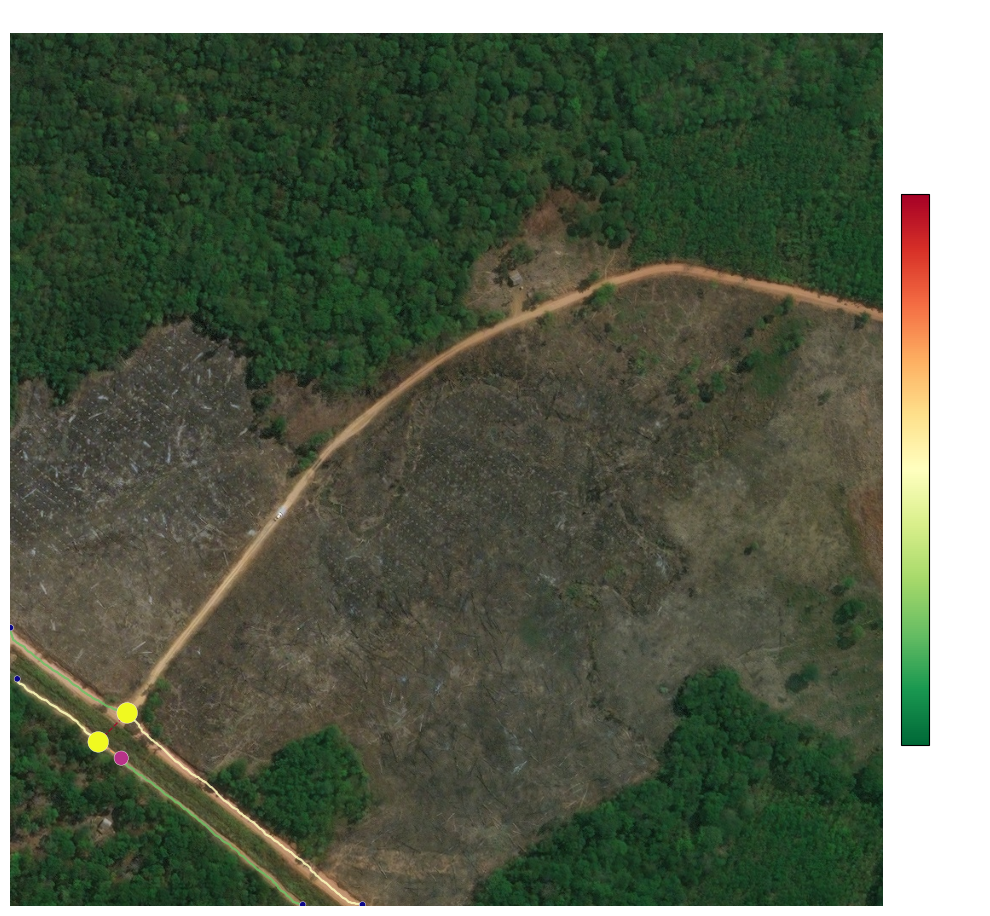

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/54635_criticality.png

Analyzing 55062_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/55062_criticality.json


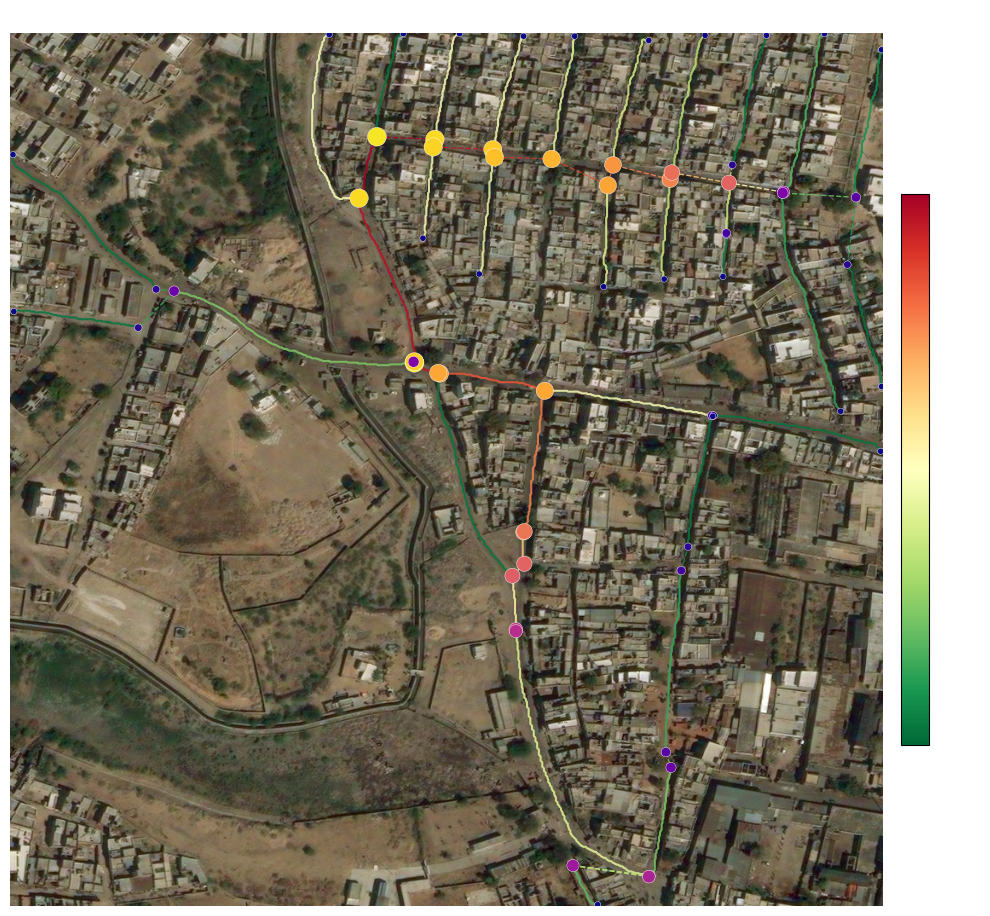

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/55062_criticality.png

Analyzing 597644_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/597644_criticality.json


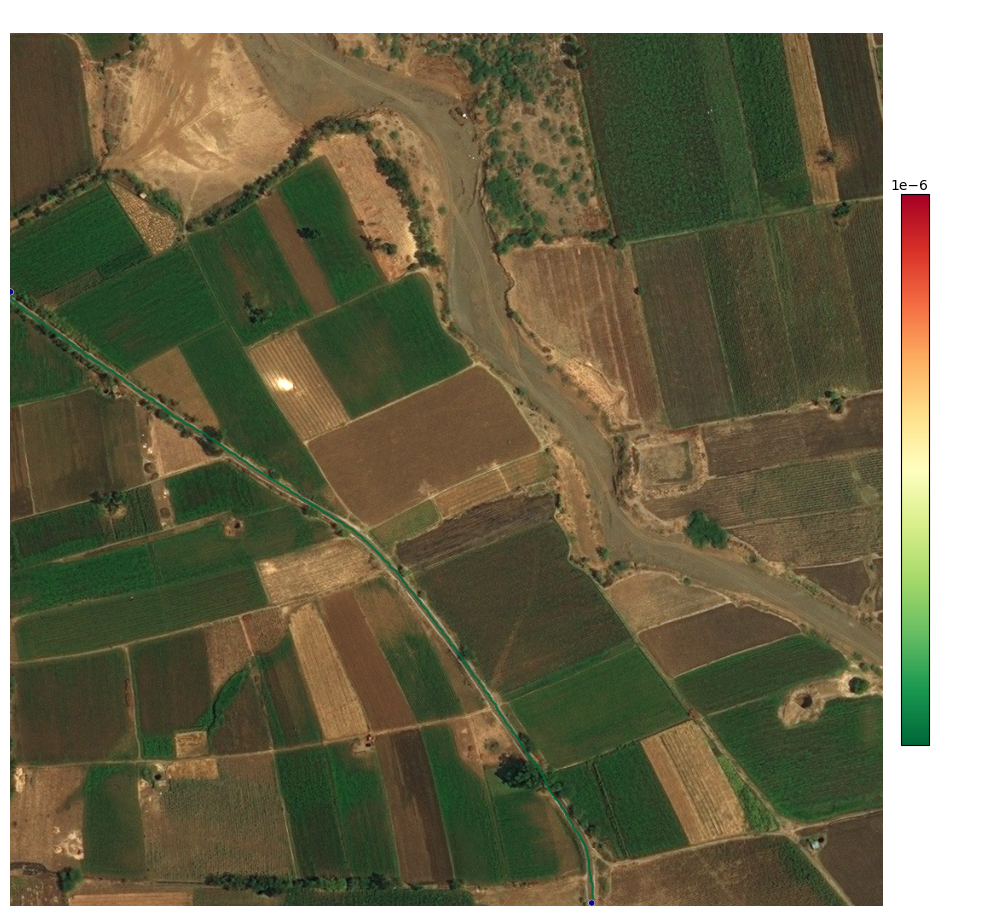

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/597644_criticality.png

Analyzing 616654_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/616654_criticality.json


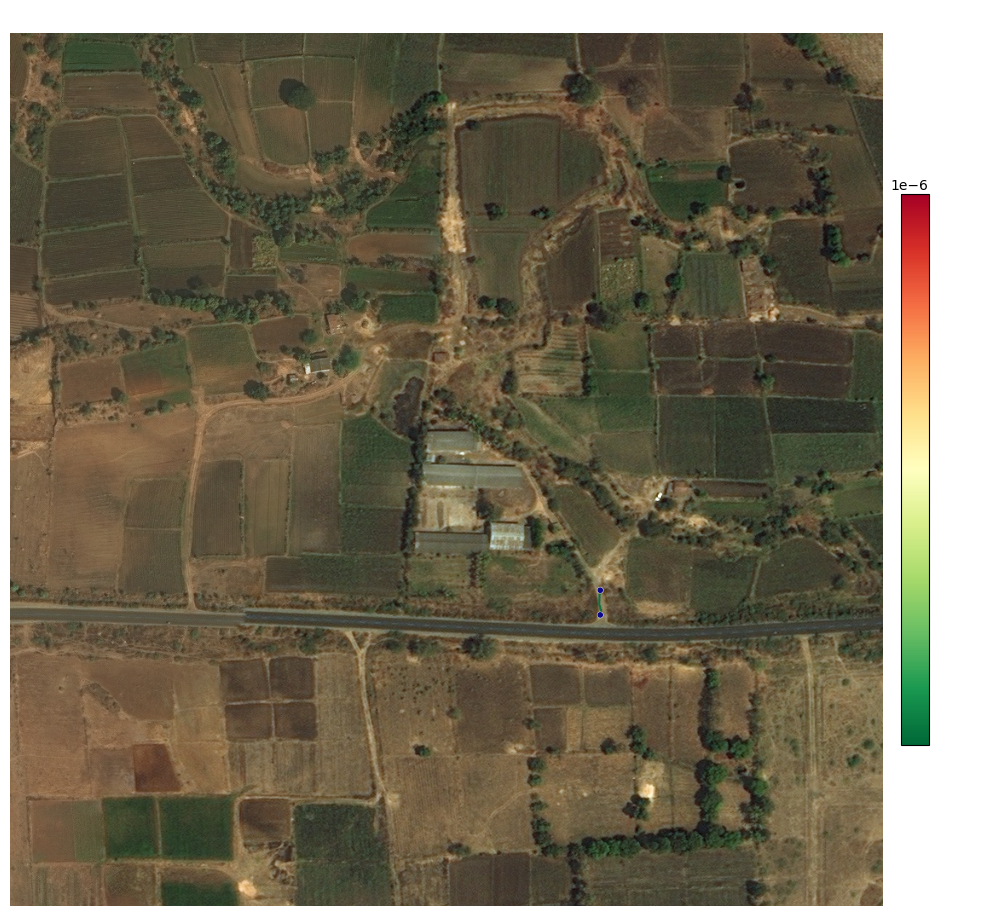

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/616654_criticality.png

Analyzing 632438_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/632438_criticality.json


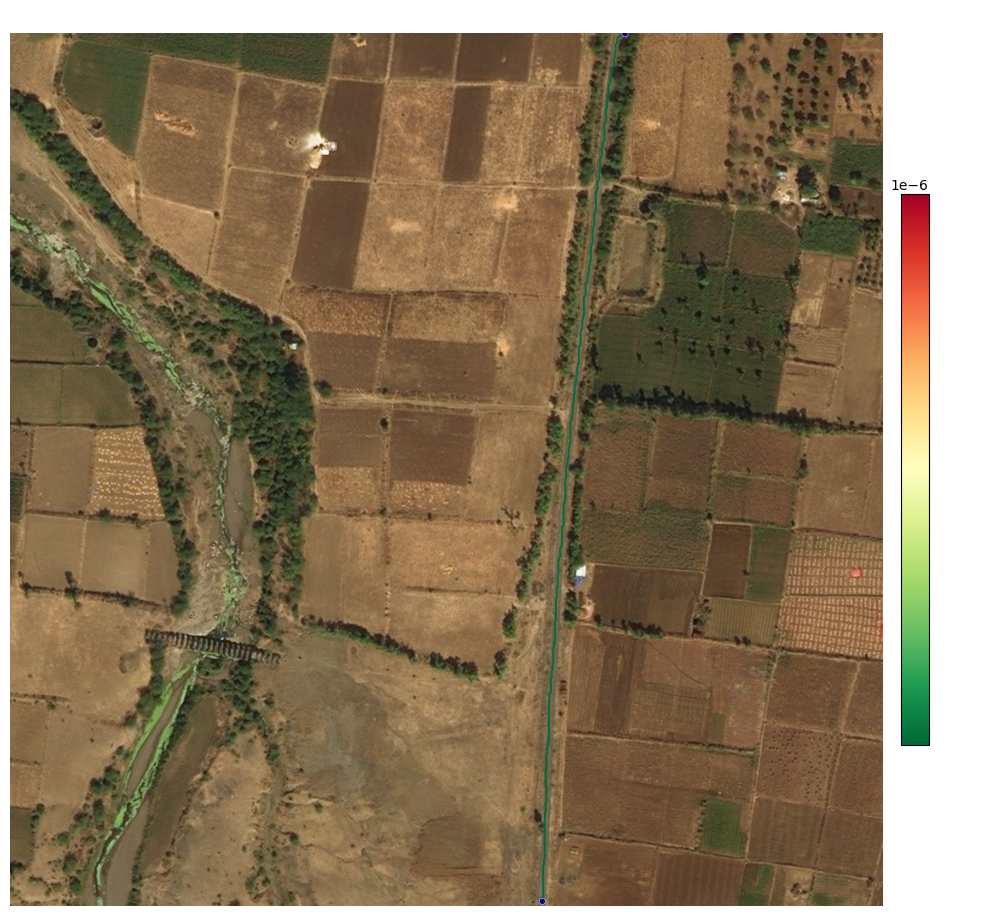

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/632438_criticality.png

Analyzing 642961_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/642961_criticality.json


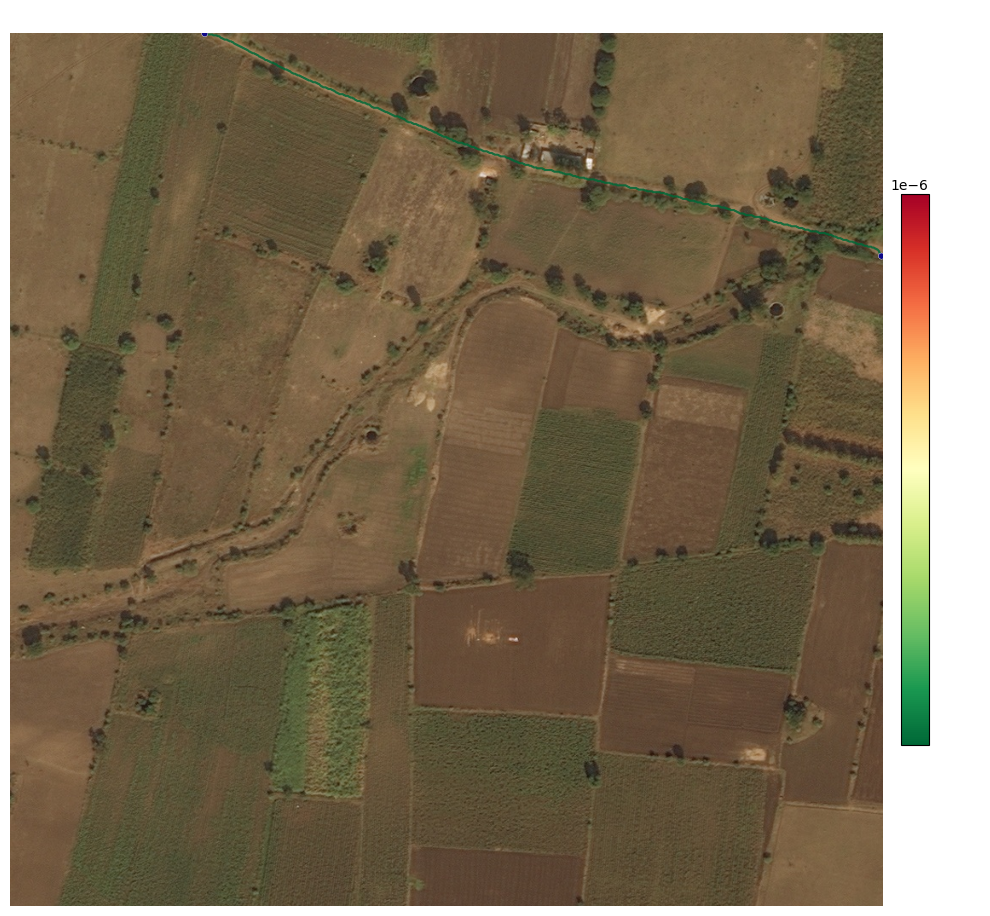

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/642961_criticality.png

Analyzing 666341_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/666341_criticality.json


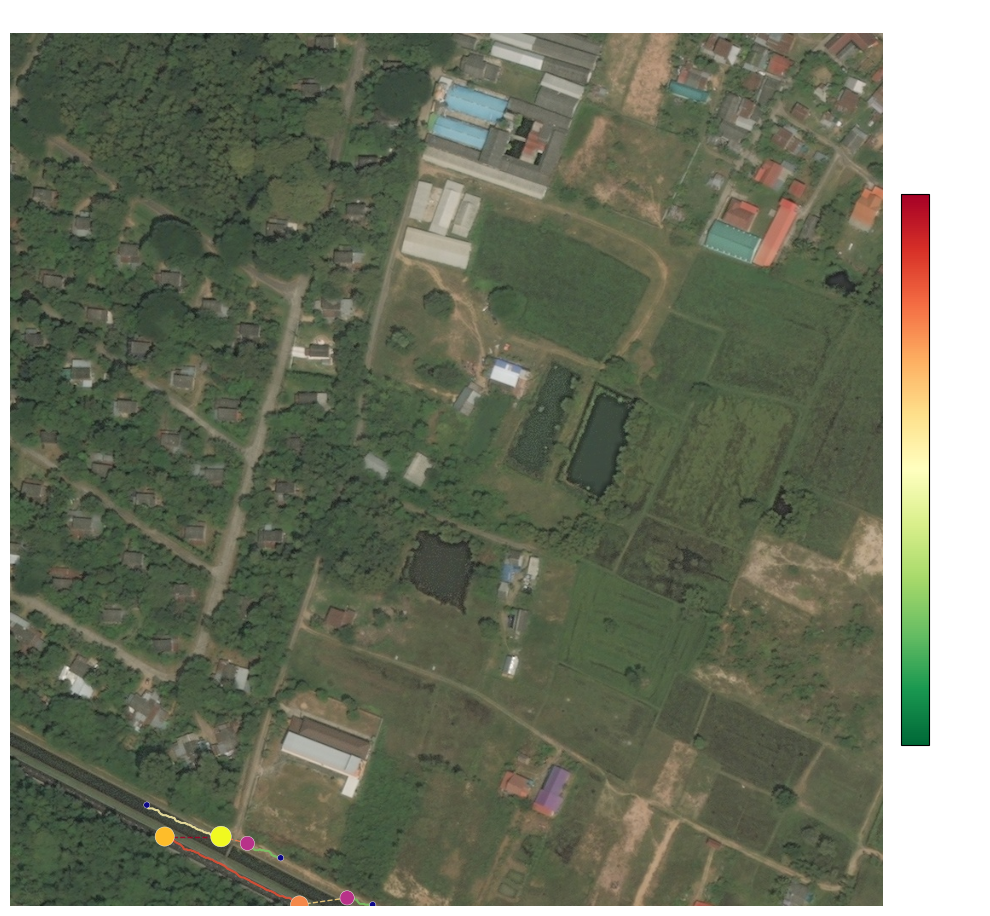

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/666341_criticality.png

Analyzing 684145_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/684145_criticality.json


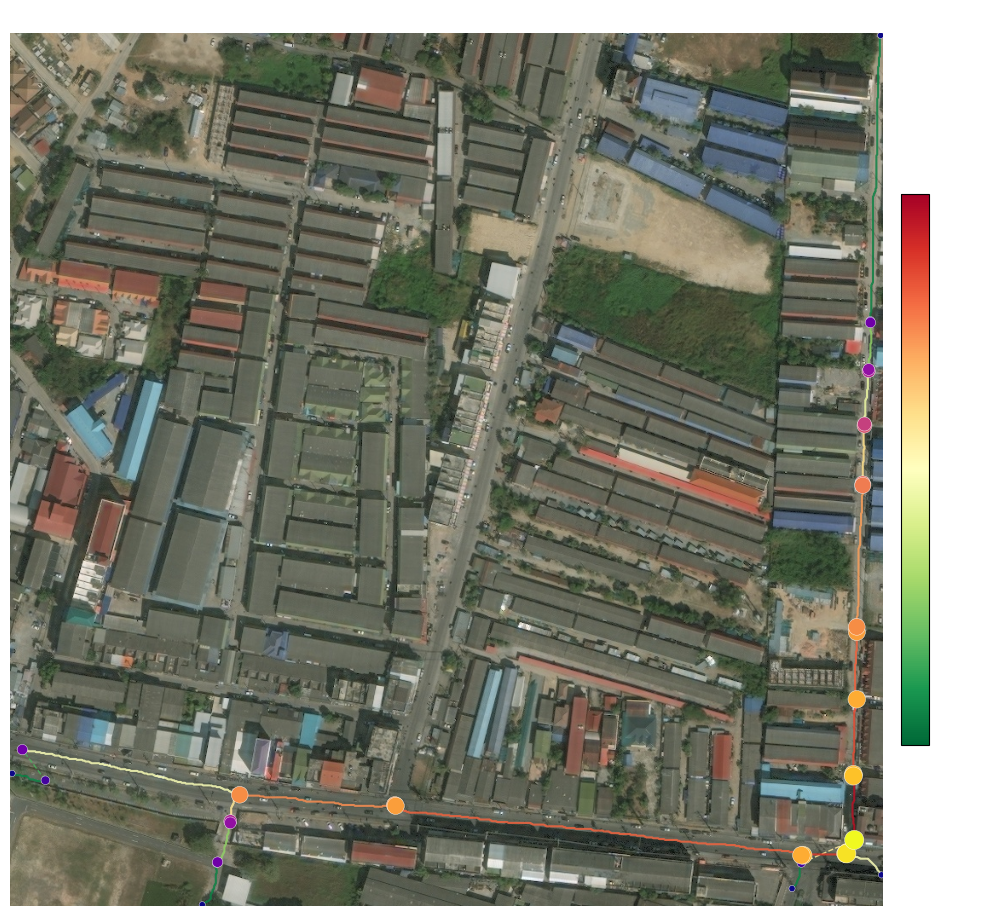

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/684145_criticality.png

Analyzing 742461_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/742461_criticality.json


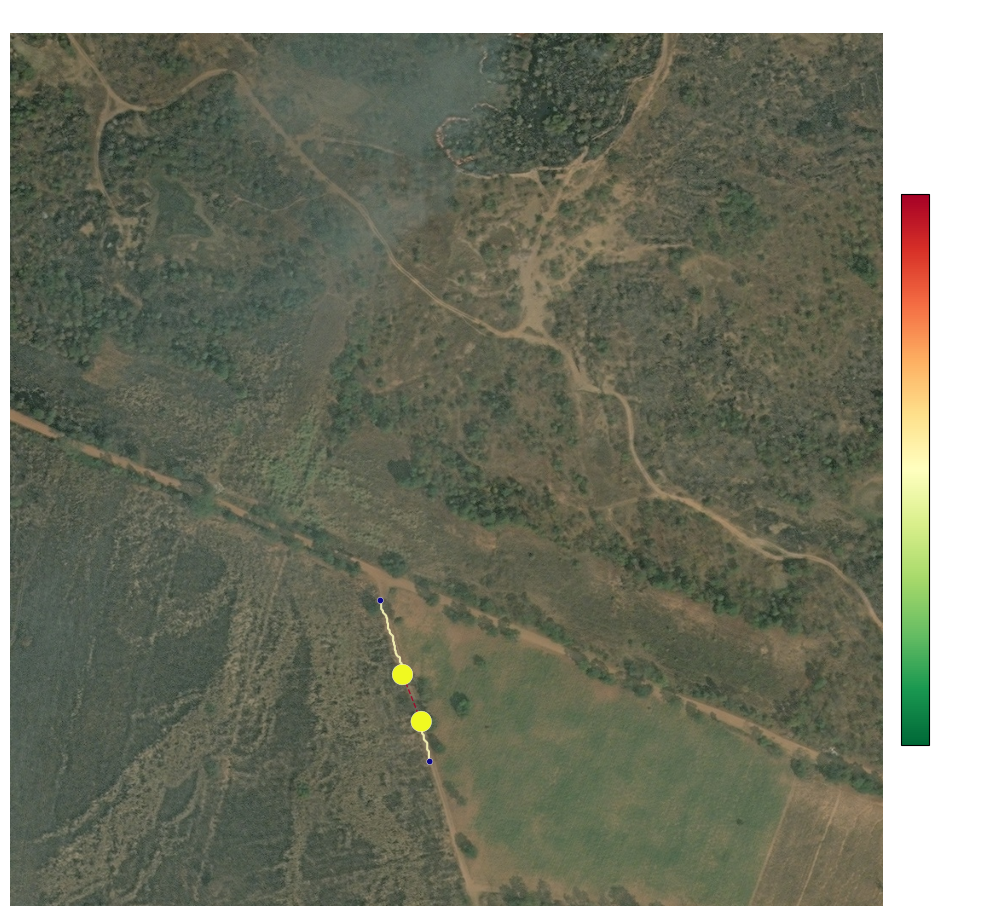

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/742461_criticality.png

Analyzing 77085_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/77085_criticality.json


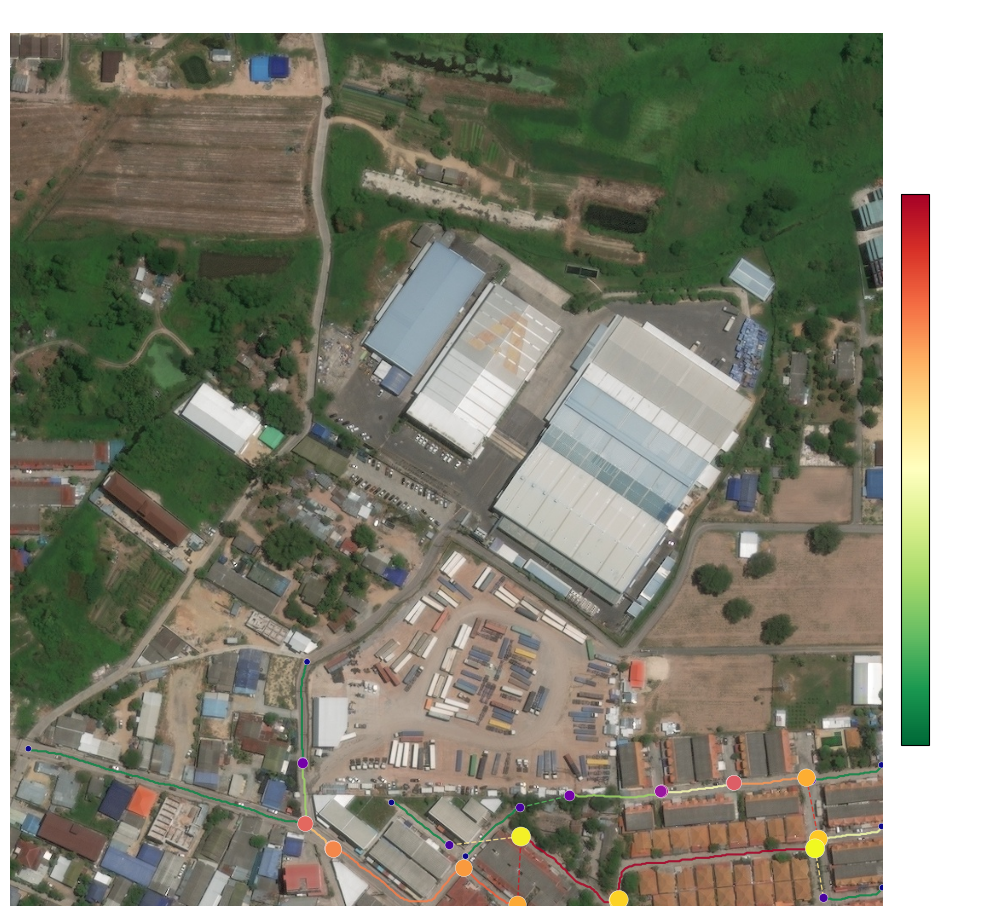

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/77085_criticality.png

Analyzing 774511_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/774511_criticality.json


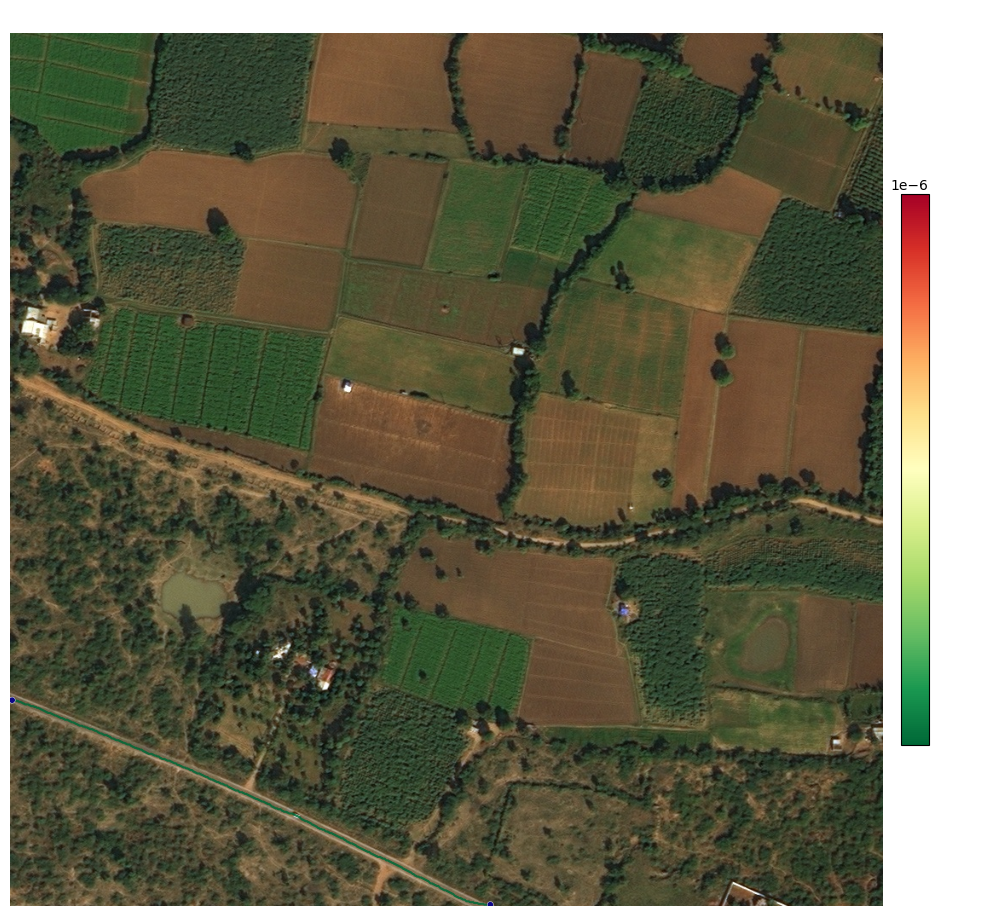

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/774511_criticality.png

Analyzing 790349_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/790349_criticality.json


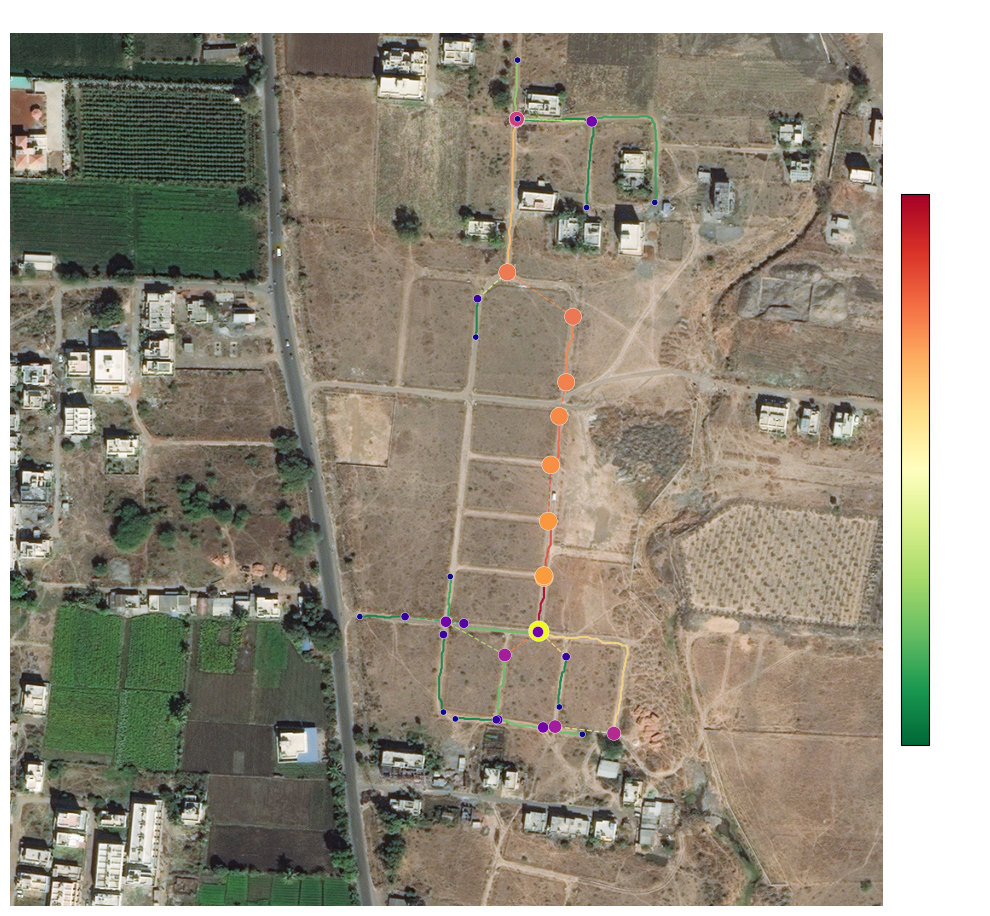

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/790349_criticality.png

Analyzing 816528_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/816528_criticality.json


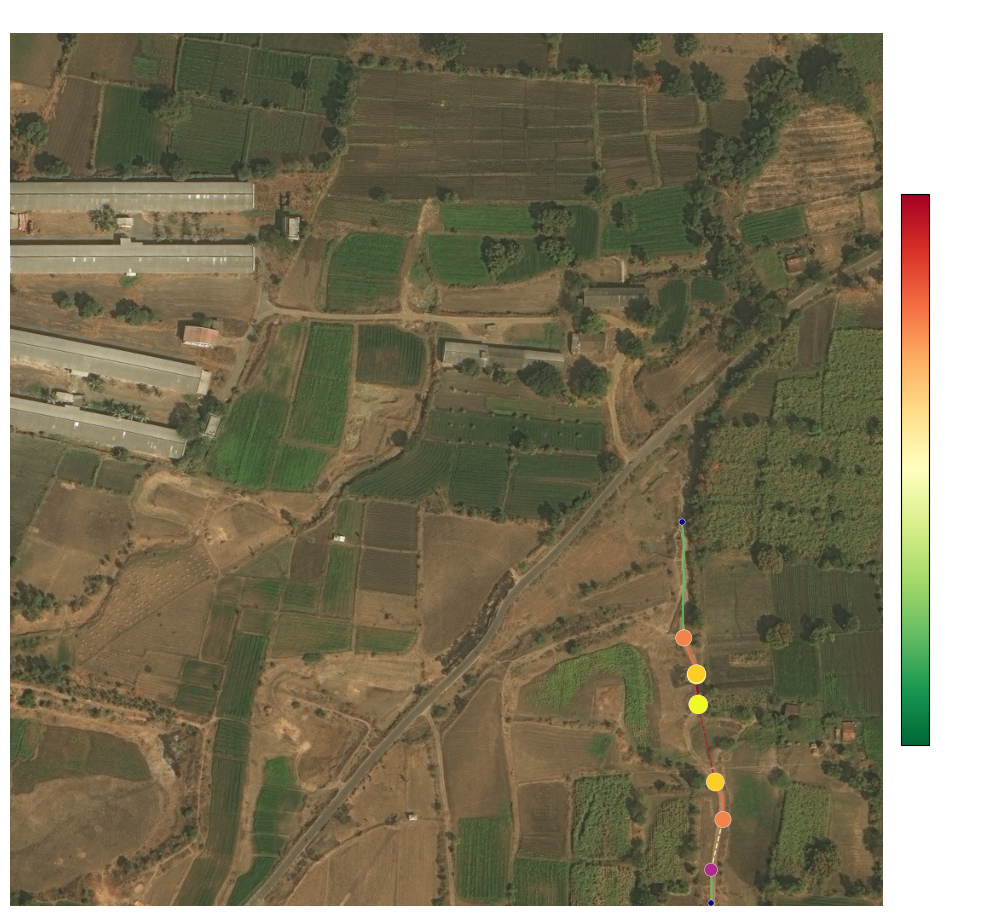

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/816528_criticality.png

Analyzing 817650_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/817650_criticality.json


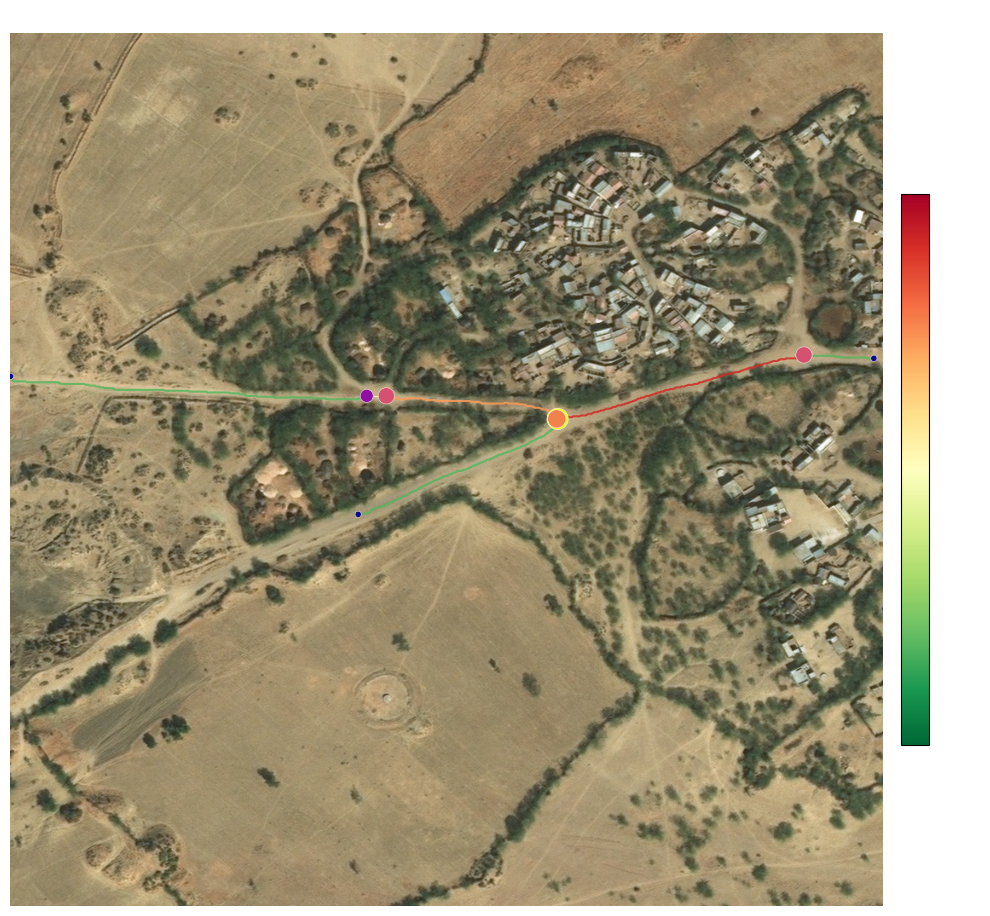

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/817650_criticality.png

Analyzing 825359_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/825359_criticality.json


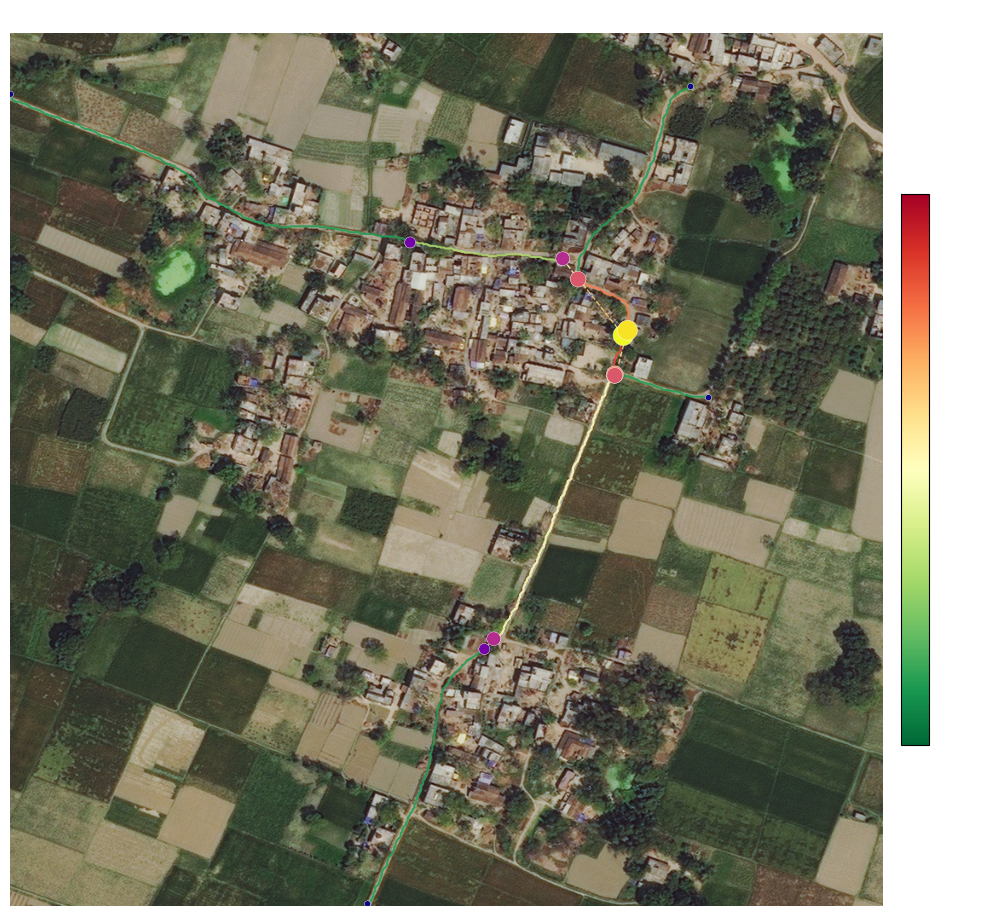

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/825359_criticality.png

Analyzing 906484_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/906484_criticality.json


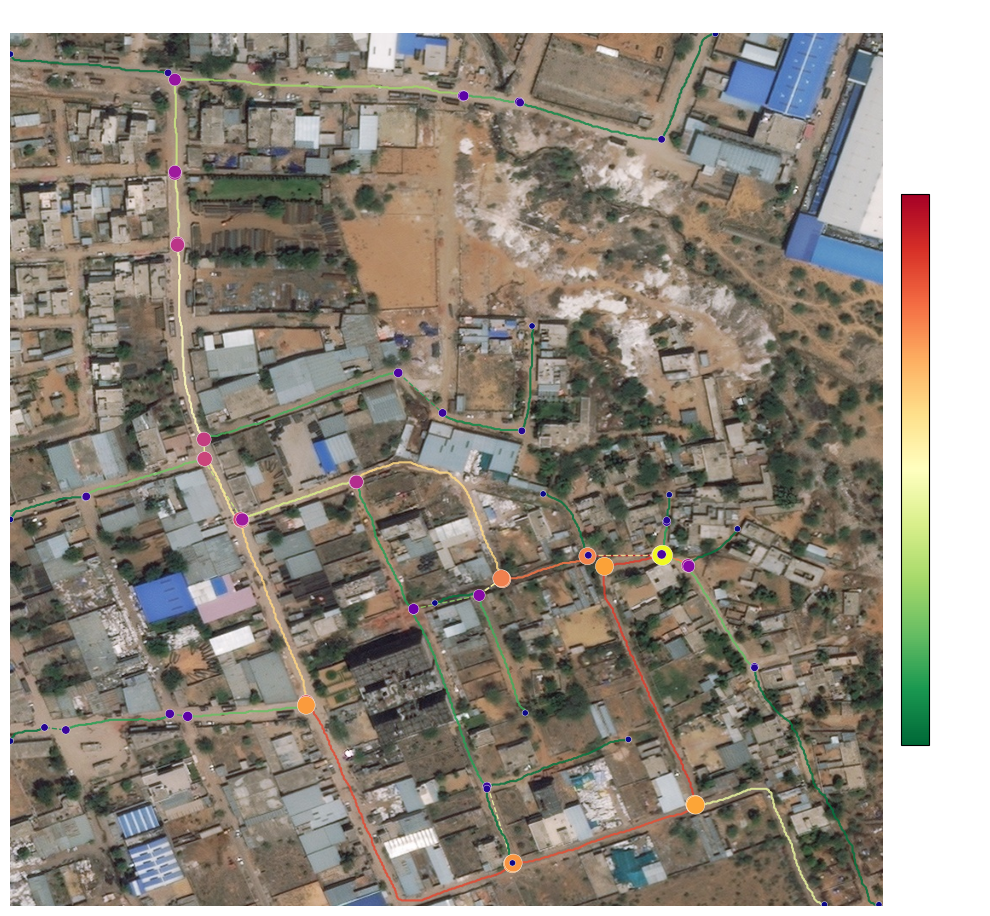

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/906484_criticality.png

Analyzing 919932_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/919932_criticality.json


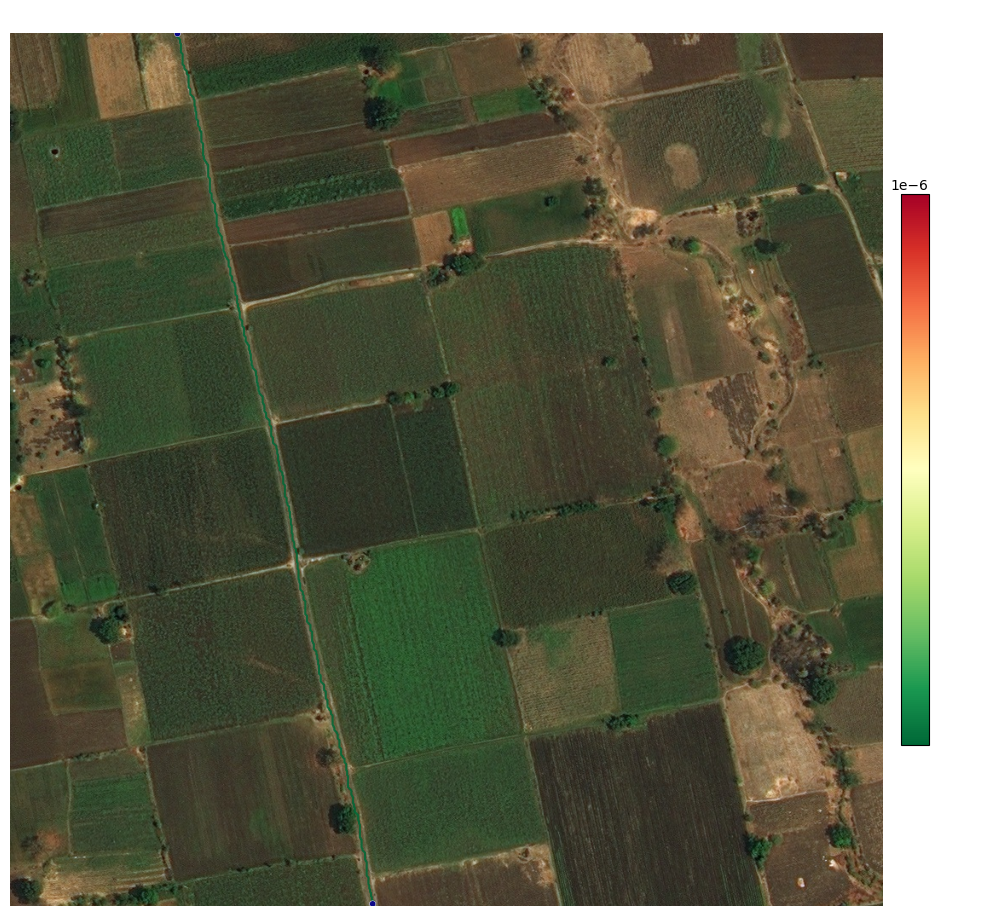

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/919932_criticality.png

Analyzing 920694_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/920694_criticality.json


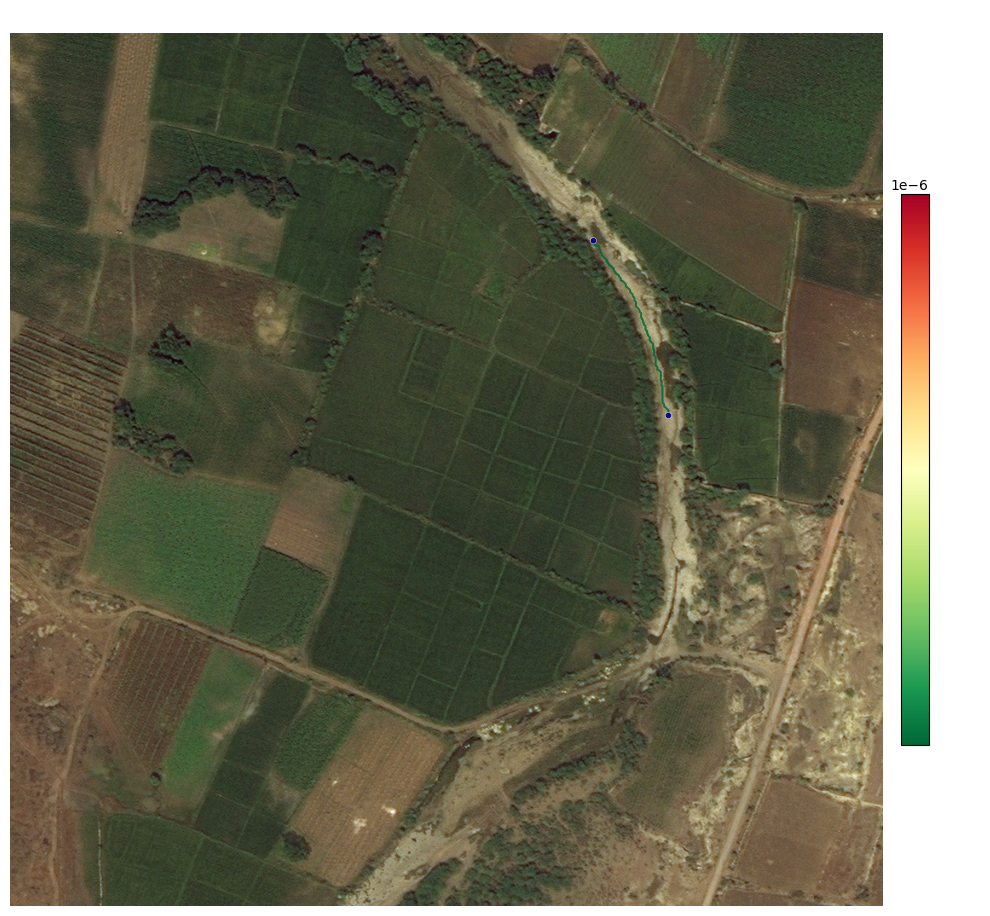

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/920694_criticality.png

Analyzing 941572_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/941572_criticality.json


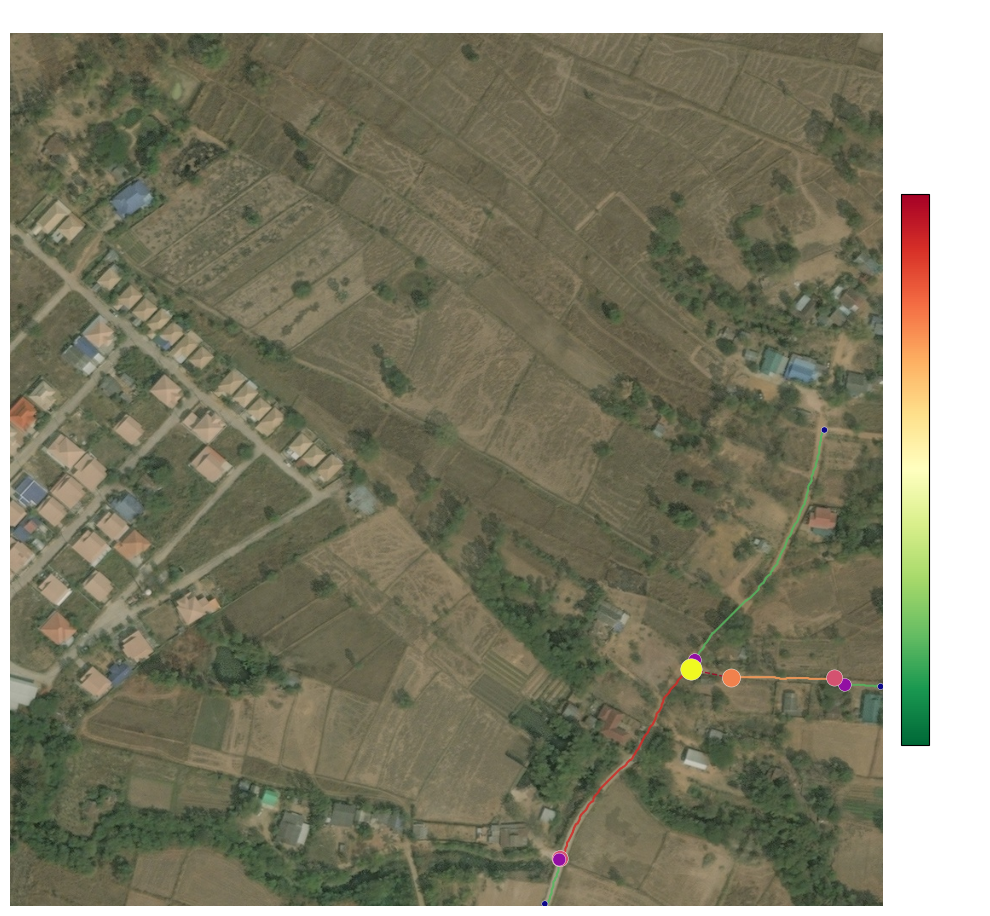

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/941572_criticality.png

Analyzing 942296_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/942296_criticality.json


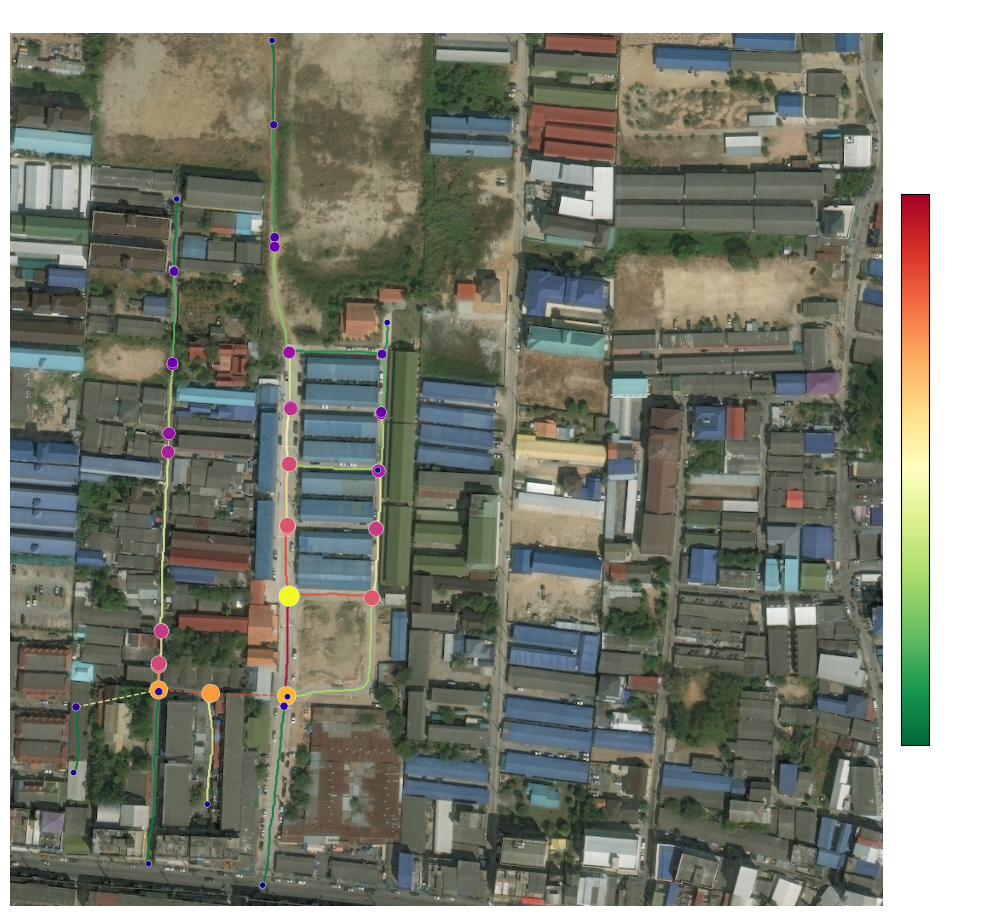

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/942296_criticality.png

Analyzing 961236_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/961236_criticality.json


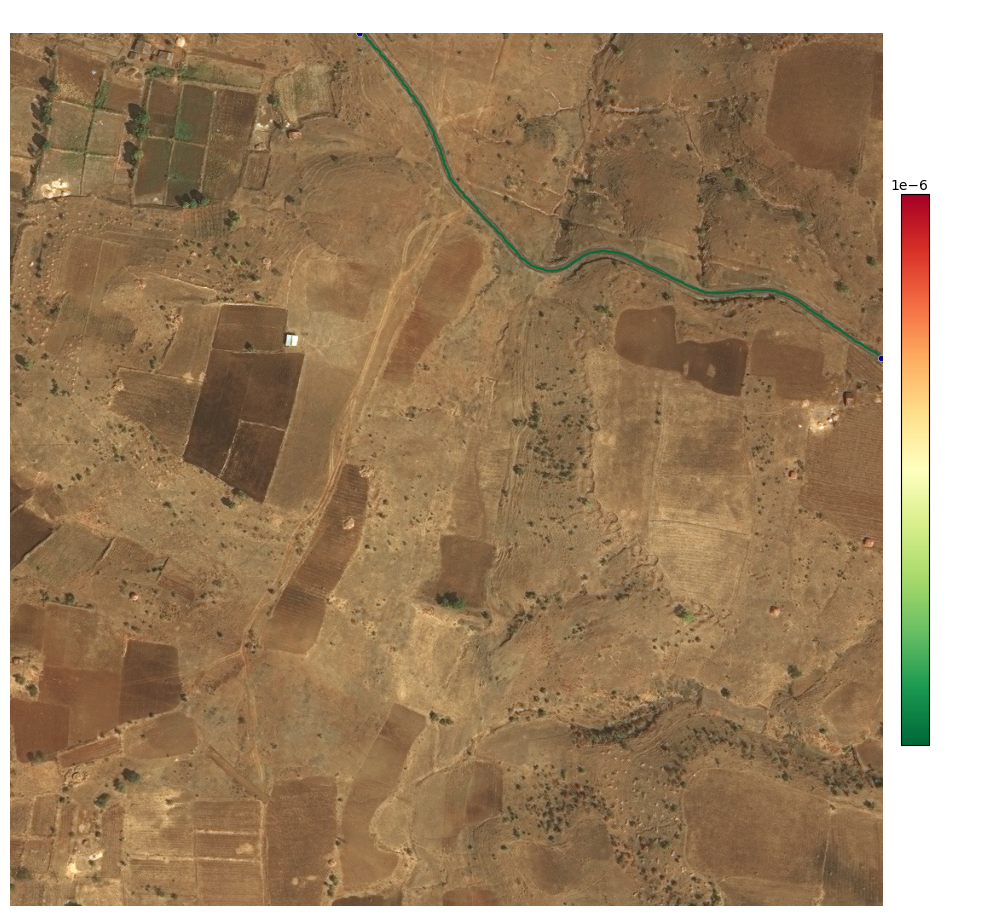

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/961236_criticality.png

Analyzing 993412_graph.json
Saved analysis -> /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/993412_criticality.json


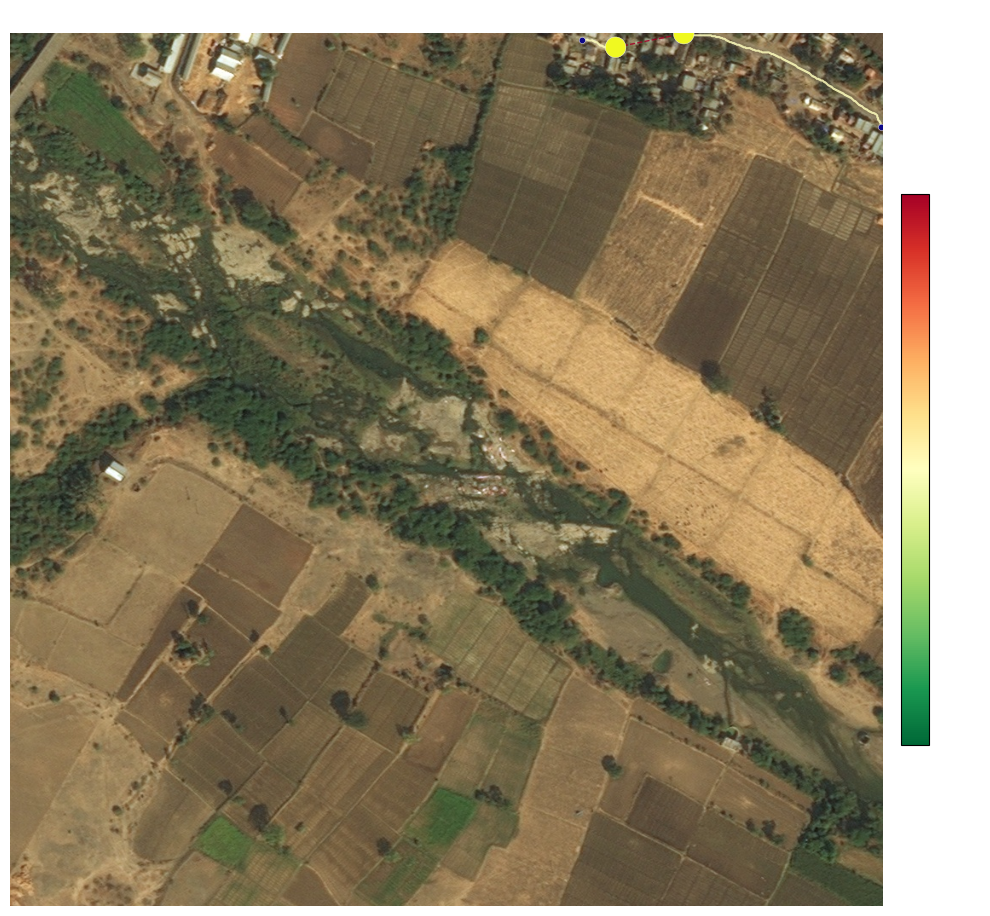

Saved heatmap -> /content/drive/MyDrive/RouteResilience/outputs/analysis_viz_deeplabv3/993412_criticality.png

summary
image_id | nodes | edges | baseline_L | top_gatekeeper | top_bc | resilience_R | components_after_top_removal
-------------------------------------------------------------------------------------------------------------
109889   | 15    | 14    | 420.7789   | n86            | 0.5385 | 1.8299       | 2                           
127572   | 2     | 1     | 1076.0     | n1             | 0.0    | 0.0          | 1                           
161528   | 10    | 9     | 446.912    | n32            | 0.5556 | 1.8413       | 2                           
188924   | 32    | 31    | 799.8907   | n38            | 0.5634 | 1.7798       | 3                           
194764   | 2     | 1     | 137.0      | n7             | 0.0    | 0.0          | 1                           
288657   | 16    | 15    | 491.2386   | n14            | 0.6286 | 1.4189       | 3                           
3

In [9]:
def analyze_graph(graph_path):
    G_full, image_id = load_graph_from_json(graph_path)
    G = largest_component(G_full)

    if G.number_of_nodes() < 2:
        print(f"[SKIP] {image_id}: largest component has < 2 nodes")
        return None

    sat_path = f"{DATA_DIR}/{image_id}_sat.jpg"
    sat_img = cv2.cvtColor(cv2.imread(sat_path), cv2.COLOR_BGR2RGB) if os.path.exists(sat_path) else None
    if sat_img is None:
        print(f"[WARN] {image_id}: no satellite tile found at {sat_path} — plotting on a blank background")

    bc = compute_betweenness(G)
    gatekeepers, ranked = rank_gatekeepers(G, bc, top_k=TOP_K)
    baseline_len = avg_path_length(G)
    ablation = run_ablation_study(G, ranked, baseline_len, top_k=TOP_K)

    payload = build_dashboard_json(image_id, G, gatekeepers, bc, baseline_len, ablation)
    save_analysis(payload)
    plot_criticality(G, bc, image_id, sat_img=sat_img)

    top = gatekeepers[0] if gatekeepers else {}
    worst = ablation[0] if ablation else {}
    return {
        "image_id": image_id,
        "nodes": G.number_of_nodes(),
        "edges": G.number_of_edges(),
        "baseline_L": round(baseline_len, 4),
        "top_gatekeeper": top.get("id", "—"),
        "top_bc": top.get("betweenness", 0.0),
        "resilience_R": worst.get("resilience_index", 0.0),
        "components_after_top_removal": worst.get("connected_components", 0),
    }


summary_rows = []
for graph_path in graph_files:
    print("\n" + "=" * 60)
    print(f"Analyzing {os.path.basename(graph_path)}")
    row = analyze_graph(graph_path)
    if row:
        summary_rows.append(row)

print("\n" + "=" * 60)
print("summary")
print("=" * 60)

if summary_rows:
    headers = ["image_id", "nodes", "edges", "baseline_L", "top_gatekeeper", "top_bc", "resilience_R", "components_after_top_removal"]
    widths = {h: max(len(h), *(len(str(r[h])) for r in summary_rows)) for h in headers}
    header_line = " | ".join(h.ljust(widths[h]) for h in headers)
    print(header_line)
    print("-" * len(header_line))
    for row in summary_rows:
        print(" | ".join(str(row[h]).ljust(widths[h]) for h in headers))
else:
    print("No graphs were successfully analyzed.")

print(f"\nDone. {len(summary_rows)} / {len(graph_files)} graphs exported to {ANALYSIS_DIR}")


In [11]:
import pandas as pd
import os

# Check if the summary_rows list exists in memory
if 'summary_rows' in locals() and summary_rows:
    print("Generating quantifiable metrics table...\n")

    # Convert the raw dictionary data into a DataFrame
    df = pd.DataFrame(summary_rows)

    # Rename the columns to presentation-ready titles
    df.rename(columns={
        "image_id": "Network ID",
        "nodes": "Total Nodes",
        "edges": "Total Edges",
        "baseline_L": "Baseline Path Length (L)",
        "top_gatekeeper": "Vulnerable Node ID",
        "top_bc": "Max Centrality Score",
        "resilience_R": "Resilience Index",
        "components_after_top_removal": "Islands After Failure"
    }, inplace=True)

    # Display the clean table directly in the Jupyter/Colab output
    display(df)

    # Save the table as a CSV in your Phase III analysis folder
    csv_path = os.path.join(ANALYSIS_DIR, f"{MODEL_NAME}_criticality_metrics.csv")
    df.to_csv(csv_path, index=False)

    print(f"\n✅ Data saved successfully to: {csv_path}")

else:
    print("Error: 'summary_rows' not found. Please run the analysis cell above this one first.")

Generating quantifiable metrics table...



,Network ID,Total Nodes,Total Edges,Baseline Path Length (L),Vulnerable Node ID,Max Centrality Score,Resilience Index,Islands After Failure
0,109889,15,14,420.7789,n86,0.5385,1.8299,2
1,127572,2,1,1076.0000,n1,0.0000,0.0000,1
2,161528,10,9,446.9120,n32,0.5556,1.8413,2
3,188924,32,31,799.8907,n38,0.5634,1.7798,3
4,194764,2,1,137.0000,n7,0.0000,0.0000,1
5,288657,16,15,491.2386,n14,0.6286,1.4189,3
6,356917,26,25,702.4265,n60,0.5467,1.6222,4
7,375903,2,1,817.0000,n0,0.0000,0.0000,1
8,392410,6,5,345.5684,n9,0.6000,4.3043,2
9,393111,12,11,395.4107,n85,0.5455,2.5419,2



✅ Data saved successfully to: /content/drive/MyDrive/RouteResilience/outputs/analysis_deeplabv3/deeplabv3_criticality_metrics.csv
